# Trabajo Práctico III - Preprocesamiento y extracción de características para búsquedas por similitud

Gestión Avanzada de Datos - UTN FRCU

Alumno: Manuel Riedel

Objetivo. Construir representaciones de imágenes, textos y sonidos, utilizarlas para recuperar objetos similares y evaluar cómo las decisiones de preprocesamiento y extracción modifican los resultados. Se reutilizan las funciones de distancia de los TP anteriores.

Modalidad. Resolver los ejercicios 1 a 9 mediante notebooks o scripts reproducibles. No se requiere entrenar redes, desarrollar una interfaz ni implementar un índice aproximado. Los modelos se utilizan preentrenados y congelados, en modo evaluación.

Datos usados. Las fotos se armaron con objetos reales del dataset COIL-100 (Columbia University), recortados de su fondo negro y pegados sobre cuatro fondos (madera, mantel, pared y escritorio), con iluminación y ángulo distintos en cada foto. Los audios se generaron con la voz Eddy (español de México) del sintetizador de macOS, cada repetición por separado y a distinta velocidad, con un ruido de fondo leve. Si se cambian los archivos de `datos/originales` por fotos y grabaciones propias con los mismos nombres, el notebook corre igual.

Para correrlo hacen falta estas librerías (la primera vez se descargan los pesos de ResNet50, BGE-M3 y wav2vec 2.0):

In [1]:
# !pip install torch torchvision transformers librosa soundfile scikit-learn nltk spacy pandas matplotlib pillow
# !python -m spacy download es_core_news_sm

In [2]:
import logging
import os

# menos avisos de las librerías de modelos
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['HF_HUB_VERBOSITY'] = 'error'
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'
logging.getLogger('torch.distributed.elastic.multiprocessing.redirects').setLevel(logging.ERROR)

import platform
import re
import subprocess
import time
import unicodedata
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 250)
plt.rcParams['figure.dpi'] = 90
%config InlineBackend.figure_formats = ['jpeg']

DATOS = Path('datos')
ORIG = DATOS / 'originales'
PROC = DATOS / 'procesados'
CARAC = DATOS / 'caracteristicas'
RES = DATOS / 'resultados'
for carpeta in [ORIG / 'imagenes', ORIG / 'sonido', ORIG / 'texto', PROC / 'imagenes', PROC / 'sonido', CARAC, RES]:
    carpeta.mkdir(parents=True, exist_ok=True)

SEMILLA = 0

Funciones comunes a todos los buscadores. La búsqueda es exhaustiva: cada consulta se compara con toda la base. Los empates se resuelven por ID ascendente. Si una consulta no tiene vector (norma cero) no se devuelven resultados y sus métricas valen 0.

In [3]:
def normalizar_l2(v):
    n = np.linalg.norm(v)
    return v / n if n > 0 else v


def dist_coseno(Q, B):
    Q, B = np.asarray(Q, dtype=np.float64), np.asarray(B, dtype=np.float64)
    nq = np.linalg.norm(Q, axis=1, keepdims=True)
    nb = np.linalg.norm(B, axis=1, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        D = 1 - (Q / nq) @ (B / nb).T
    D[nq[:, 0] == 0] = np.nan  # consulta sin vector
    return np.clip(D, 0, 2)


def dist_euclidiana(Q, B):
    Q, B = np.asarray(Q, dtype=np.float64), np.asarray(B, dtype=np.float64)
    d2 = (Q ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * Q @ B.T
    return np.sqrt(np.maximum(d2, 0))


def top_k(fila, ids, k=3):
    if np.all(np.isnan(fila)):
        return []
    # redondeo a 10 decimales para que el punto flotante no rompa un empate
    orden = sorted(range(len(ids)), key=lambda j: (round(float(fila[j]), 10), ids[j]))
    return [(ids[j], float(fila[j])) for j in orden[:k]]


EVALUACION = []    # consultas principales
EXPERIMENTOS = []  # variantes (brillo, ruido, repetición, consulta sin términos)


def evaluar(modalidad, representacion, consultas, base, D, relevantes, explicar, guardar=True):
    filas = []
    for i, q in enumerate(consultas):
        top = top_k(D[i], base)
        n = sum(b in relevantes[q] for b, _ in top)
        filas.append({'modalidad': modalidad, 'representacion': representacion, 'consulta': q,
                      'top3': ', '.join(b for b, _ in top) if top else 'sin resultados',
                      'distancias': ', '.join(f'{d:.4f}' for _, d in top),
                      'relevantes': n, 'P@3': n / 3, 'R@3': n / len(relevantes[q]),
                      'por qué': ' / '.join(f'{b}: {explicar(q, b)}' for b, _ in top) if top else 'consulta sin vector'})
    if guardar:
        EVALUACION.extend(filas)
    return pd.DataFrame(filas)


def mostrar(tabla, columnas=('consulta', 'top3', 'distancias', 'relevantes', 'P@3', 'R@3')):
    return tabla[list(columnas)].style.format({'P@3': '{:.4f}', 'R@3': '{:.4f}'}).hide(axis='index')

## Ejercicio 1. Preparar tres colecciones de búsqueda

Se implementarán tres buscadores independientes. Las etiquetas sirven únicamente para evaluar la recuperación, no se incorporan a los vectores ni se usan para entrenar clasificadores.

| Modalidad | Colección y consultas | Qué significa relevante |
|---|---|---|
| Imágenes | 6 objetos físicos, con 3 fotos de base y 1 foto de consulta por objeto: 18 + 6 imágenes. | Otra fotografía del mismo objeto físico. |
| Texto | Los 12 documentos y las 6 consultas incluidos en el ejercicio 4. | Un documento que responda la consulta, según la lista de relevancia. |
| Sonido | 4 frases, con 3 grabaciones de base y 1 de consulta por frase: 12 + 4 audios. | Otra grabación de la misma frase, aunque cambie el ritmo. |

a) Crear carpetas separadas para originales, datos procesados, características y resultados. Asignar identificadores estables y registrar en un manifiesto: ID, archivo, modalidad, base o consulta, objeto/frase de origen y condiciones de captura.

b) En imágenes, incluir objetos de color parecido pero distinta forma y objetos de forma parecida pero distinto color. Tomar fotos separadas, variando moderadamente fondo, iluminación y ángulo. Las consultas deben ser capturas nuevas, no copias de fotos de la base.

c) Para sonido, usar las frases del ejercicio 7. Mantener un mismo hablante en el experimento principal para estudiar ritmo y representación. Grabar cada repetición por separado, con voz natural y duración de 2 a 5 segundos.

d) Definir antes de ejecutar los buscadores los pares consulta-documento relevantes. En imagen y sonido, cada consulta tiene exactamente 3 objetos relevantes en la base. Conservar esta definición durante todas las comparaciones.

Reglas comunes de implementación. Ajustar paletas, vocabularios, IDF y estadísticas de estandarización solamente con la base. Guardarlos y reutilizarlos sin reajustar para las consultas. No comparar vectores de extractores distintos, aunque tengan la misma dimensión. Resolver empates por ID ascendente y excluir las consultas de la base. La evaluación usa búsqueda exhaustiva: comparar cada consulta con toda la base. Descargar los pesos una vez y reutilizarlos, procesar de a un objeto si la memoria es limitada.

In [4]:
DOCS = {
    'D01': 'Para restablecer una contraseña olvidada, ingresá tu correo en la opción Recuperar acceso.',
    'D02': 'Si no recordás la clave, solicitá un enlace de recuperación por correo electrónico.',
    'D03': 'Para cambiar una contraseña conocida, ingresá a tu perfil y elegí Seguridad.',
    'D04': 'La biblioteca presta libros a domicilio durante siete días.',
    'D05': 'El préstamo de libros de la biblioteca dura una semana y puede renovarse.',
    'D06': 'La sala de lectura de la biblioteca abre de lunes a viernes.',
    'D07': 'El curso de C++ requiere conocimientos previos de programación.',
    'D08': 'Para inscribirse en C++ es necesario saber programar.',
    'D09': 'El curso introductorio de Python no requiere conocimientos previos de programación.',
    'D10': 'Python inicial está destinado a personas que nunca programaron.',
    'D11': 'La beca de transporte cubre viajes en colectivo para asistir a clases.',
    'D12': 'Para pedir ayuda económica para el transporte, completá el formulario de becas.',
}
CONSULTAS_TEXTO = {
    'Q1': 'Olvidé mi contraseña. ¿Cómo recupero el acceso?',
    'Q2': 'No recuerdo mi clave. ¿Me pueden enviar un enlace?',
    'Q3': '¿Cuántos días puedo llevarme un libro a casa?',
    'Q4': '¿Puedo cursar C++ sin saber programar?',
    'Q5': 'Nunca programé. ¿Hay un curso para empezar con Python?',
    'Q6': '¿Qué ayuda hay para pagar el colectivo a la facultad?',
}
REL_TEXTO = {'Q1': ['D01', 'D02'], 'Q2': ['D01', 'D02'], 'Q3': ['D04', 'D05'],
             'Q4': ['D07', 'D08'], 'Q5': ['D09', 'D10'], 'Q6': ['D11', 'D12']}
FRASES = {'F1': 'La biblioteca abre por la mañana.', 'F2': 'La biblioteca cierra por la mañana.',
          'F3': 'El laboratorio abre por la tarde.', 'F4': 'El laboratorio cierra por la tarde.'}

# copia literal de cada texto
for i, t in {**DOCS, **CONSULTAS_TEXTO}.items():
    (ORIG / 'texto' / f'{i}.txt').write_text(t, encoding='utf-8')

cond_img = pd.read_csv(ORIG / 'condiciones_imagenes.csv').set_index('id')
cond_son = pd.read_csv(ORIG / 'condiciones_sonido.csv').set_index('id')

filas = []
for p in sorted((ORIG / 'imagenes').glob('*.png')):
    _, obj, rol = p.stem.split('_')
    c = cond_img.loc[p.stem]
    filas.append({'id': p.stem, 'archivo': p.as_posix(), 'modalidad': 'imagen', 'rol': 'consulta' if rol == 'Q' else 'base',
                  'origen': f'{obj} ({c.descripcion})',
                  'condiciones': f'fondo {c.fondo}, luz {c.iluminacion}, ángulo {c.angulo}, objeto {c.objeto_coil} de COIL-100'})
for p in sorted((ORIG / 'texto').glob('*.txt')):
    es_q = p.stem.startswith('Q')
    filas.append({'id': p.stem, 'archivo': p.as_posix(), 'modalidad': 'texto', 'rol': 'consulta' if es_q else 'base',
                  'origen': 'consulta del enunciado' if es_q else 'documento del enunciado', 'condiciones': 'copia literal'})
for p in sorted((ORIG / 'sonido').glob('*.wav')):
    _, fr, rol = p.stem.split('_')
    c = cond_son.loc[p.stem]
    filas.append({'id': p.stem, 'archivo': p.as_posix(), 'modalidad': 'sonido', 'rol': 'consulta' if rol == 'Q' else 'base',
                  'origen': f'{fr} ({FRASES[fr]})',
                  'condiciones': f'{c.voz}, {c.velocidad_palabras_min} palabras/min, silencio {c.silencio_inicial_ms} y '
                                 f'{c.silencio_final_ms} ms, {c.formato}, {c.ambiente}'})
manifiesto = pd.DataFrame(filas)
manifiesto.to_csv(DATOS / 'manifiesto.csv', index=False)
print(manifiesto.groupby(['modalidad', 'rol']).size())
manifiesto.head(8)

modalidad  rol     
imagen     base        18
           consulta     6
sonido     base        12
           consulta     4
texto      base        12
           consulta     6
dtype: int64


,id,archivo,modalidad,rol,origen,condiciones
0,IMG_O1_B1,datos/originales/imagenes/IMG_O1_B1.png,imagen,base,O1 (aro rojo),"fondo madera, luz normal, ángulo 0 grados, objeto obj47 de COIL-100"
1,IMG_O1_B2,datos/originales/imagenes/IMG_O1_B2.png,imagen,base,O1 (aro rojo),"fondo mantel, luz tenue, ángulo 40 grados, objeto obj47 de COIL-100"
2,IMG_O1_B3,datos/originales/imagenes/IMG_O1_B3.png,imagen,base,O1 (aro rojo),"fondo pared, luz fuerte, ángulo 320 grados, objeto obj47 de COIL-100"
3,IMG_O1_Q,datos/originales/imagenes/IMG_O1_Q.png,imagen,consulta,O1 (aro rojo),"fondo escritorio, luz algo tenue, ángulo 20 grados, objeto obj47 de COIL-100"
4,IMG_O2_B1,datos/originales/imagenes/IMG_O2_B1.png,imagen,base,O2 (aro azul),"fondo mantel, luz normal, ángulo 0 grados, objeto obj94 de COIL-100"
5,IMG_O2_B2,datos/originales/imagenes/IMG_O2_B2.png,imagen,base,O2 (aro azul),"fondo pared, luz tenue, ángulo 40 grados, objeto obj94 de COIL-100"
6,IMG_O2_B3,datos/originales/imagenes/IMG_O2_B3.png,imagen,base,O2 (aro azul),"fondo escritorio, luz fuerte, ángulo 320 grados, objeto obj94 de COIL-100"
7,IMG_O2_Q,datos/originales/imagenes/IMG_O2_Q.png,imagen,consulta,O2 (aro azul),"fondo pared, luz algo tenue, ángulo 20 grados, objeto obj94 de COIL-100"


Relevancia definida antes de correr cualquier buscador: en imagen y sonido son las 3 fotos o grabaciones de base del mismo objeto o frase, en texto la lista del enunciado.

In [5]:
base_img = manifiesto.query("modalidad == 'imagen' and rol == 'base'").id.tolist()
cons_img = manifiesto.query("modalidad == 'imagen' and rol == 'consulta'").id.tolist()
base_son = manifiesto.query("modalidad == 'sonido' and rol == 'base'").id.tolist()
cons_son = manifiesto.query("modalidad == 'sonido' and rol == 'consulta'").id.tolist()
base_txt, cons_txt = list(DOCS), list(CONSULTAS_TEXTO)

RELEVANTES = {}
for q in cons_img:
    RELEVANTES[q] = [b for b in base_img if b.split('_')[1] == q.split('_')[1]]
for q in cons_son:
    RELEVANTES[q] = [b for b in base_son if b.split('_')[1] == q.split('_')[1]]
RELEVANTES.update(REL_TEXTO)

relevancia = pd.DataFrame([{'modalidad': 'imagen' if q.startswith('IMG') else 'sonido' if q.startswith('SON') else 'texto',
                            'consulta': q, 'relevantes': ', '.join(r)} for q, r in RELEVANTES.items()])
relevancia.to_csv(DATOS / 'relevancia.csv', index=False)
assert all(len(RELEVANTES[q]) == 3 for q in cons_img + cons_son)
relevancia

,modalidad,consulta,relevantes
0,imagen,IMG_O1_Q,"IMG_O1_B1, IMG_O1_B2, IMG_O1_B3"
1,imagen,IMG_O2_Q,"IMG_O2_B1, IMG_O2_B2, IMG_O2_B3"
2,imagen,IMG_O3_Q,"IMG_O3_B1, IMG_O3_B2, IMG_O3_B3"
3,imagen,IMG_O4_Q,"IMG_O4_B1, IMG_O4_B2, IMG_O4_B3"
4,imagen,IMG_O5_Q,"IMG_O5_B1, IMG_O5_B2, IMG_O5_B3"
5,imagen,IMG_O6_Q,"IMG_O6_B1, IMG_O6_B2, IMG_O6_B3"
6,sonido,SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F1_B3"
7,sonido,SON_F2_Q,"SON_F2_B1, SON_F2_B2, SON_F2_B3"
8,sonido,SON_F3_Q,"SON_F3_B1, SON_F3_B2, SON_F3_B3"
9,sonido,SON_F4_Q,"SON_F4_B1, SON_F4_B2, SON_F4_B3"


a) La carpeta `datos/` tiene cuatro subcarpetas: `originales` (fotos, audios y textos sin tocar), `procesados` (imágenes de 224 x 224 y audios mono de 16 kHz recortados), `caracteristicas` (vectores, paleta, vocabulario e IDF) y `resultados` (grillas, gráficos y tablas). Los IDs son estables y dicen qué es cada archivo: IMG_O1_B1 es la foto 1 de base del objeto 1, IMG_O1_Q es su consulta, SON_F2_B3 es la tercera grabación de base de la frase 2, y los textos usan los IDs del enunciado. El manifiesto con ID, archivo, modalidad, rol, origen y condiciones está en `datos/manifiesto.csv`.

b) Los seis objetos forman pares a propósito. Comparten forma con distinto color el aro rojo y el aro azul, el morrón rojo y el morrón verde, y el barco azul y el barco verde. Comparten color con distinta forma el aro rojo y el morrón rojo, el aro azul y el barco azul, y el morrón verde y el barco verde. Cada foto tiene otro fondo (madera, mantel, pared o escritorio), otra luz y otro ángulo del objeto (0, 40 y 320 grados en la base y 20 grados en la consulta), así que la consulta no es copia de ninguna foto de la base. Los fondos se repiten entre objetos distintos para que el fondo solo no identifique al objeto.

c) Las 16 grabaciones tienen la misma voz. Cada repetición se generó por separado con otra velocidad (175, 190 y 205 palabras por minuto en la base y 140 en la consulta, que queda más lenta) y con silencio al principio y al final. Duran entre 2.5 y 3.5 segundos.

d) La relevancia quedó fijada en `datos/relevancia.csv` antes de correr los buscadores y no se cambió después. En imagen y sonido cada consulta tiene exactamente 3 relevantes en la base.

Explicaciones de por qué cada resultado sirve o no (se usan en el ejercicio 9).

In [6]:
DESC_OBJ = {i.split('_')[1]: d for i, d in cond_img.descripcion.items()}
FONDO = cond_img.fondo.to_dict()
TEMA = {'D01': 'recuperar una contraseña olvidada', 'D02': 'pedir un enlace para recuperar la clave',
        'D03': 'cambiar una contraseña que se conoce', 'D04': 'el préstamo de libros a domicilio por siete días',
        'D05': 'la duración del préstamo de libros', 'D06': 'el horario de la sala de lectura',
        'D07': 'los requisitos del curso de C++', 'D08': 'los requisitos para inscribirse en C++',
        'D09': 'el curso de Python sin requisitos', 'D10': 'el curso de Python para quien nunca programó',
        'D11': 'la beca de transporte', 'D12': 'cómo pedir la ayuda para el transporte'}


def explicar_img(q, b):
    oq, ob = q.split('_')[1], b.split('_')[1]
    if oq == ob:
        return 'sí, otra foto del mismo objeto'
    fq, cq = DESC_OBJ[oq].split()
    fb, cb = DESC_OBJ[ob].split()
    motivos = [m for m, ok in [('el color', cq == cb), ('la forma', fq == fb), (f'el fondo ({FONDO[b]})', FONDO[q] == FONDO[b])] if ok]
    return f'no, es el {DESC_OBJ[ob]}' + (', comparte ' + ' y '.join(motivos) if motivos else ', no comparte color, forma ni fondo')


def explicar_txt(q, d):
    return ('sí, ' if d in REL_TEXTO[q] else 'no, ') + f'habla de {TEMA[d]}'


def explicar_son(q, b):
    fq, fb = q.split('_')[1], b.split('_')[1]
    if fq == fb:
        return 'sí, otra grabación de la misma frase'
    cambios = [f'{x} por {y}' for x, y in zip(FRASES[fq].lower().strip('.').split(), FRASES[fb].lower().strip('.').split())
               if x != y and x not in ('la', 'el')]
    return f'no, es {fb}, cambia ' + ' y '.join(cambios)

## Ejercicio 2. Imágenes con píxeles e histogramas

Una oficina quiere encontrar otras fotos de un objeto extraviado. Primero se probarán dos descriptores sencillos para observar cuándo el fondo o el color pesan más que la identidad del objeto.

a) Leer las imágenes como RGB, si se usa OpenCV, convertir desde BGR. Mantener los originales y generar una versión de 224 × 224 píxeles. Elegir y documentar una política común de recorte o conservación de proporciones.

original: (320, 240) RGB -> procesada: (224, 224)


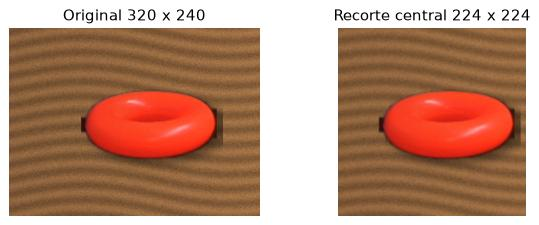

In [7]:
def leer_rgb(id_):
    return Image.open(ORIG / 'imagenes' / f'{id_}.png').convert('RGB')


def a_224(im):
    # política: recorte central cuadrado del lado menor y reducción a 224 x 224 (bilineal con antialias)
    w, h = im.size
    lado = min(w, h)
    x0, y0 = (w - lado) // 2, (h - lado) // 2
    return im.crop((x0, y0, x0 + lado, y0 + lado)).resize((224, 224), Image.BILINEAR)


ids_img = base_img + cons_img
ORIGINALES = {i: leer_rgb(i) for i in ids_img}
IMG224 = {i: a_224(ORIGINALES[i]) for i in ids_img}
for i, im in IMG224.items():
    im.save(PROC / 'imagenes' / f'{i}.png')
print('original:', ORIGINALES[cons_img[0]].size, ORIGINALES[cons_img[0]].mode, '-> procesada:', IMG224[cons_img[0]].size)

fig, ax = plt.subplots(1, 2, figsize=(7, 2.6))
ax[0].imshow(ORIGINALES['IMG_O1_B1']); ax[0].set_title('Original 320 x 240')
ax[1].imshow(IMG224['IMG_O1_B1']); ax[1].set_title('Recorte central 224 x 224')
for a in ax:
    a.axis('off')
plt.tight_layout(); plt.savefig(RES / 'ej2_recorte.jpg', dpi=120, pil_kwargs={'quality': 88}); plt.show()

Leo cada imagen con PIL y la convierto a RGB (no uso OpenCV, así que no hay que pasar de BGR). Los originales quedan en `datos/originales/imagenes` y la versión de 224 x 224 en `datos/procesados/imagenes`. La política común es recortar el cuadrado central del lado menor (240 x 240 en una foto de 320 x 240) y reducirlo a 224 x 224 con interpolación bilineal. Así el objeto no se deforma, y como está cerca del centro el recorte solo saca fondo de los costados.

b) Descriptor de píxeles: escalar los valores a [0,1], aplanar y normalizar a norma L2 unitaria. Informar su dimensión y explicar qué representa cada coordenada.

In [8]:
def desc_pixeles(im224):
    v = np.asarray(im224, dtype=np.float32).reshape(-1) / 255
    return normalizar_l2(v)


PIX = {i: desc_pixeles(IMG224[i]) for i in ids_img}
v = PIX[cons_img[0]]
print('dimensión:', v.shape[0], '= 224 * 224 * 3')
print('norma mínima y máxima:', min(np.linalg.norm(x) for x in PIX.values()), max(np.linalg.norm(x) for x in PIX.values()))
# coordenada k -> fila, columna y canal
k = 1000
print(f'la coordenada {k} es la fila {k // (224 * 3)}, columna {(k // 3) % 224}, canal {"RGB"[k % 3]}')

dimensión: 150528 = 224 * 224 * 3
norma mínima y máxima: 0.9999997 1.0000006
la coordenada 1000 es la fila 1, columna 109, canal G


El vector tiene 224 x 224 x 3 = 150528 coordenadas. Cada coordenada es la intensidad de un canal (rojo, verde o azul) en un píxel fijo, recorriendo la imagen fila por fila. Por ejemplo, la coordenada 1000 es el canal verde del píxel de la fila 1 y columna 109. Todas las normas dan 1, salvo el redondeo de float32.

c) Descriptor de color: ajustar una única paleta k-means de 25 colores con una muestra reproducible de píxeles de la base. Asignar cada píxel al centro más cercano, contar y dividir por el total de píxeles. Guardar la paleta y el orden de sus centros. Verificar que cada histograma tiene 25 componentes y suma 1.

muestra: (36000, 3) -> paleta guardada en datos/caracteristicas/paleta_25.csv


componentes: {25}  suma mínima y máxima: 0.9999999999999999 1.0


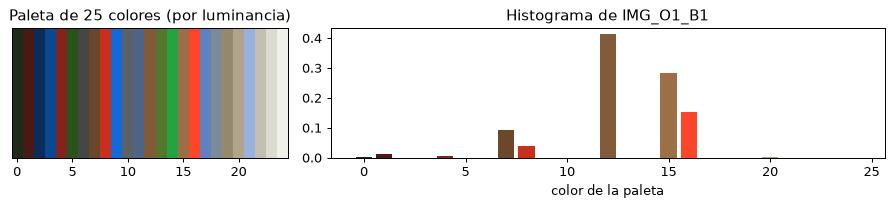

In [9]:
from sklearn.cluster import KMeans

rng = np.random.default_rng(SEMILLA)
muestra = np.concatenate([np.asarray(IMG224[b], dtype=np.float64).reshape(-1, 3)[rng.choice(224 * 224, 2000, replace=False)]
                          for b in base_img]) / 255  # 2000 píxeles por foto de base
km = KMeans(n_clusters=25, n_init=10, random_state=SEMILLA).fit(muestra)
orden = np.argsort(km.cluster_centers_ @ np.array([0.299, 0.587, 0.114]))  # centros ordenados por luminancia
PALETA = km.cluster_centers_[orden]
pd.DataFrame((PALETA * 255).round().astype(int), columns=['R', 'G', 'B']).rename_axis('color').to_csv(CARAC / 'paleta_25.csv')
print('muestra:', muestra.shape, '-> paleta guardada en', CARAC / 'paleta_25.csv')


def hist_color(im224, paleta=PALETA):
    px = np.asarray(im224, dtype=np.float64).reshape(-1, 3) / 255
    d2 = ((px[:, None, :] - paleta[None, :, :]) ** 2).sum(-1)
    return np.bincount(d2.argmin(1), minlength=len(paleta)) / len(px)


HIST = {i: hist_color(IMG224[i]) for i in ids_img}
print('componentes:', {len(h) for h in HIST.values()}, ' suma mínima y máxima:',
      min(h.sum() for h in HIST.values()), max(h.sum() for h in HIST.values()))

fig, ax = plt.subplots(1, 2, figsize=(10, 2.4), gridspec_kw={'width_ratios': [1, 2]})
ax[0].imshow(PALETA[None, :, :], aspect='auto'); ax[0].set_yticks([]); ax[0].set_title('Paleta de 25 colores (por luminancia)')
ax[1].bar(range(25), HIST['IMG_O1_B1'], color=PALETA); ax[1].set_title('Histograma de IMG_O1_B1'); ax[1].set_xlabel('color de la paleta')
plt.tight_layout(); plt.savefig(RES / 'ej2_paleta.png', dpi=120); plt.show()

np.savez_compressed(CARAC / 'imagenes_pixeles.npz', ids=np.array(ids_img), X=np.array([PIX[i] for i in ids_img], dtype=np.float32))
np.savez_compressed(CARAC / 'imagenes_histograma.npz', ids=np.array(ids_img), X=np.array([HIST[i] for i in ids_img], dtype=np.float32))

Tomé 2000 píxeles al azar de cada una de las 18 fotos de base (semilla 0), 36000 en total, y ajusté k-means con 25 centros. La paleta está en `paleta_25.csv` con los centros ordenados por luminancia, y ese orden define qué color es cada coordenada del histograma. Las consultas usan la misma paleta sin reajustar. Los 24 histogramas tienen 25 componentes y suman 1.

d) Recuperar los 3 vecinos más cercanos de cada consulta con cada descriptor, usando distancia coseno y euclidiana para ambos. Mostrar una grilla con la consulta y los resultados. Explicar por qué entrenar una paleta diferente para cada imagen invalida la comparación coordenada a coordenada.

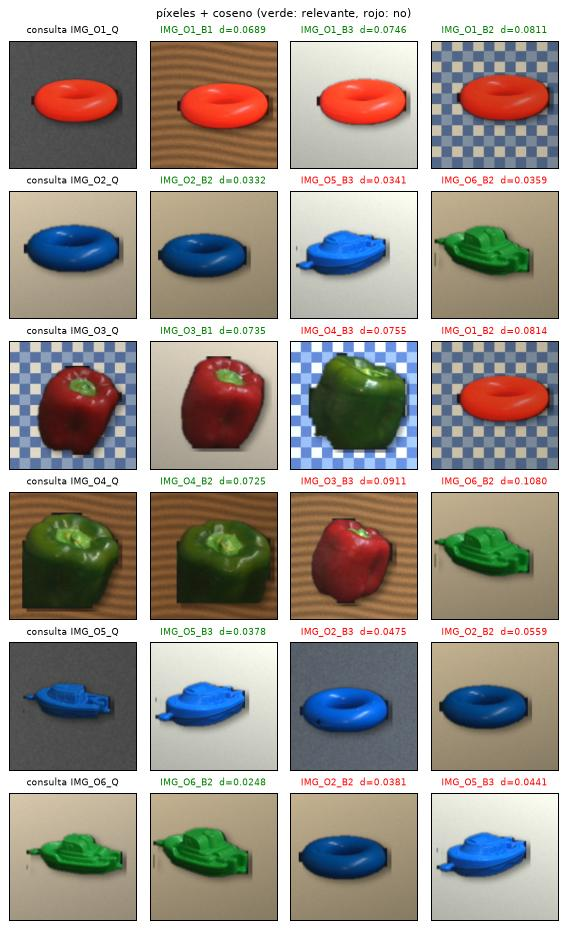

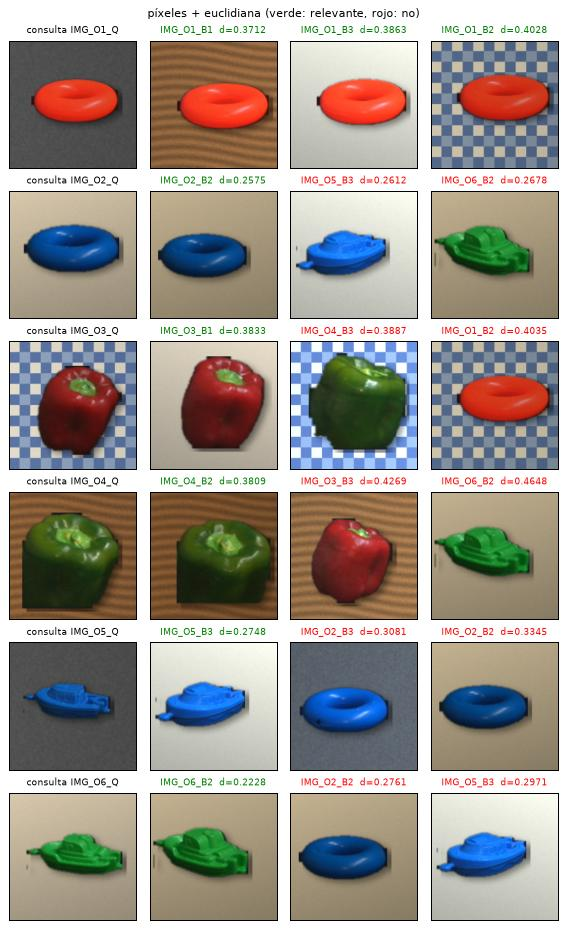

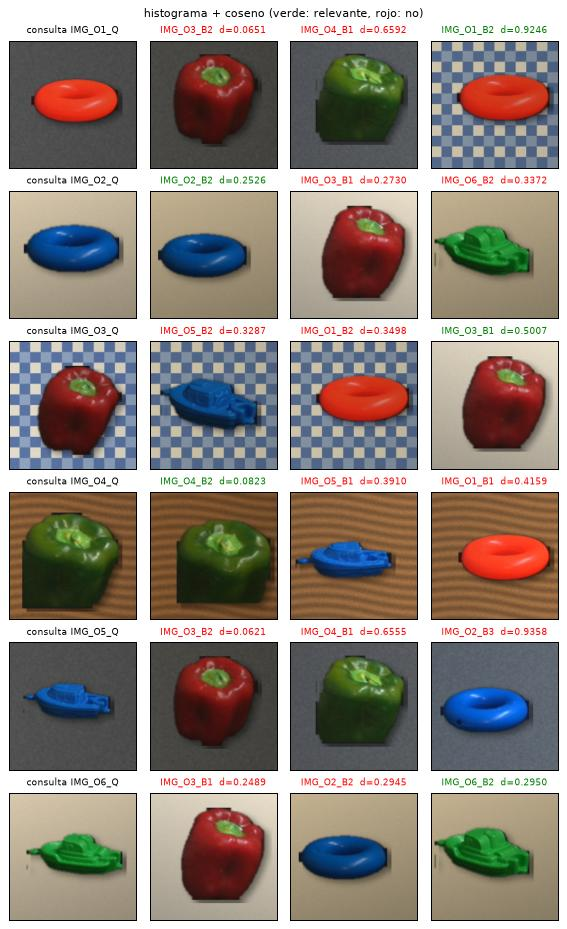

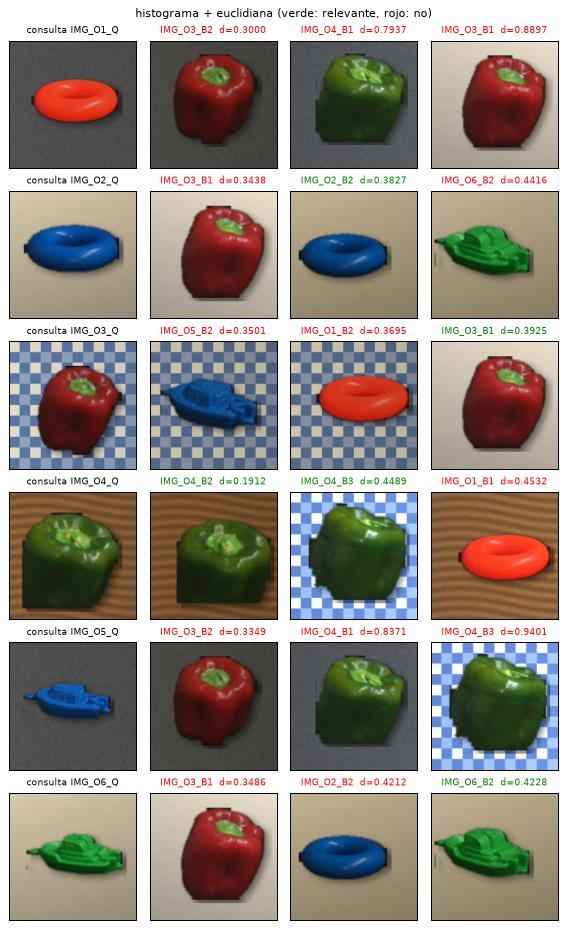

In [10]:
def matrices(desc):
    return np.array([desc[q] for q in cons_img]), np.array([desc[b] for b in base_img])


def grilla(titulo, D, archivo):
    fig, ax = plt.subplots(len(cons_img), 4, figsize=(6.4, 1.75 * len(cons_img)))
    for i, q in enumerate(cons_img):
        ax[i, 0].imshow(IMG224[q]); ax[i, 0].set_title(f'consulta {q}', fontsize=7)
        for j, (b, d) in enumerate(top_k(D[i], base_img)):
            ok = b in RELEVANTES[q]
            ax[i, j + 1].imshow(IMG224[b])
            ax[i, j + 1].set_title(f'{b}  d={d:.4f}', fontsize=7, color='green' if ok else 'red')
        for a in ax[i]:
            a.set_xticks([]); a.set_yticks([])
    fig.suptitle(titulo + ' (verde: relevante, rojo: no)', fontsize=9)
    plt.tight_layout(); plt.savefig(RES / archivo, dpi=110, pil_kwargs={'quality': 88}); plt.show()


TABLAS_IMG = {}
for nombre, desc in [('píxeles', PIX), ('histograma', HIST)]:
    Qm, Bm = matrices(desc)
    for dnombre, f in [('coseno', dist_coseno), ('euclidiana', dist_euclidiana)]:
        rep = f'{nombre} + {dnombre}'
        D = f(Qm, Bm)
        TABLAS_IMG[rep] = evaluar('imagen', rep, cons_img, base_img, D, RELEVANTES, explicar_img)
        grilla(rep, D, f"ej2_grilla_{nombre.replace('í', 'i')}_{dnombre}.jpg")

In [11]:
for rep, t in TABLAS_IMG.items():
    print(rep)
    display(mostrar(t))

píxeles + coseno


consulta,top3,distancias,relevantes,P@3,R@3
IMG_O1_Q,"IMG_O1_B1, IMG_O1_B3, IMG_O1_B2","0.0689, 0.0746, 0.0811",3,1.0000,1.0000
IMG_O2_Q,"IMG_O2_B2, IMG_O5_B3, IMG_O6_B2","0.0332, 0.0341, 0.0359",1,0.3333,0.3333
IMG_O3_Q,"IMG_O3_B1, IMG_O4_B3, IMG_O1_B2","0.0735, 0.0755, 0.0814",1,0.3333,0.3333
IMG_O4_Q,"IMG_O4_B2, IMG_O3_B3, IMG_O6_B2","0.0725, 0.0911, 0.1080",1,0.3333,0.3333
IMG_O5_Q,"IMG_O5_B3, IMG_O2_B3, IMG_O2_B2","0.0378, 0.0475, 0.0559",1,0.3333,0.3333
IMG_O6_Q,"IMG_O6_B2, IMG_O2_B2, IMG_O5_B3","0.0248, 0.0381, 0.0441",1,0.3333,0.3333


píxeles + euclidiana


consulta,top3,distancias,relevantes,P@3,R@3
IMG_O1_Q,"IMG_O1_B1, IMG_O1_B3, IMG_O1_B2","0.3712, 0.3863, 0.4028",3,1.0000,1.0000
IMG_O2_Q,"IMG_O2_B2, IMG_O5_B3, IMG_O6_B2","0.2575, 0.2612, 0.2678",1,0.3333,0.3333
IMG_O3_Q,"IMG_O3_B1, IMG_O4_B3, IMG_O1_B2","0.3833, 0.3887, 0.4035",1,0.3333,0.3333
IMG_O4_Q,"IMG_O4_B2, IMG_O3_B3, IMG_O6_B2","0.3809, 0.4269, 0.4648",1,0.3333,0.3333
IMG_O5_Q,"IMG_O5_B3, IMG_O2_B3, IMG_O2_B2","0.2748, 0.3081, 0.3345",1,0.3333,0.3333
IMG_O6_Q,"IMG_O6_B2, IMG_O2_B2, IMG_O5_B3","0.2228, 0.2761, 0.2971",1,0.3333,0.3333


histograma + coseno


consulta,top3,distancias,relevantes,P@3,R@3
IMG_O1_Q,"IMG_O3_B2, IMG_O4_B1, IMG_O1_B2","0.0651, 0.6592, 0.9246",1,0.3333,0.3333
IMG_O2_Q,"IMG_O2_B2, IMG_O3_B1, IMG_O6_B2","0.2526, 0.2730, 0.3372",1,0.3333,0.3333
IMG_O3_Q,"IMG_O5_B2, IMG_O1_B2, IMG_O3_B1","0.3287, 0.3498, 0.5007",1,0.3333,0.3333
IMG_O4_Q,"IMG_O4_B2, IMG_O5_B1, IMG_O1_B1","0.0823, 0.3910, 0.4159",1,0.3333,0.3333
IMG_O5_Q,"IMG_O3_B2, IMG_O4_B1, IMG_O2_B3","0.0621, 0.6555, 0.9358",0,0.0000,0.0000
IMG_O6_Q,"IMG_O3_B1, IMG_O2_B2, IMG_O6_B2","0.2489, 0.2945, 0.2950",1,0.3333,0.3333


histograma + euclidiana


consulta,top3,distancias,relevantes,P@3,R@3
IMG_O1_Q,"IMG_O3_B2, IMG_O4_B1, IMG_O3_B1","0.3000, 0.7937, 0.8897",0,0.0000,0.0000
IMG_O2_Q,"IMG_O3_B1, IMG_O2_B2, IMG_O6_B2","0.3438, 0.3827, 0.4416",1,0.3333,0.3333
IMG_O3_Q,"IMG_O5_B2, IMG_O1_B2, IMG_O3_B1","0.3501, 0.3695, 0.3925",1,0.3333,0.3333
IMG_O4_Q,"IMG_O4_B2, IMG_O4_B3, IMG_O1_B1","0.1912, 0.4489, 0.4532",2,0.6667,0.6667
IMG_O5_Q,"IMG_O3_B2, IMG_O4_B1, IMG_O4_B3","0.3349, 0.8371, 0.9401",0,0.0000,0.0000
IMG_O6_Q,"IMG_O3_B1, IMG_O2_B2, IMG_O6_B2","0.3486, 0.4212, 0.4228",1,0.3333,0.3333


Con píxeles, coseno y euclidiana dan exactamente el mismo ranking. Como los vectores tienen norma 1, la euclidiana al cuadrado es 2 x (1 - coseno), así que ordenan igual. El primer resultado es correcto en las seis consultas, pero el segundo y el tercero casi siempre son otro objeto del mismo color o sobre el mismo fondo (P@3 media 0.4444). Con histograma la P@3 media baja a 0.2778 con las dos distancias y pesa más el fondo que el objeto: para IMG_O1_Q (aro rojo sobre escritorio) el más cercano es IMG_O3_B2 (morrón rojo sobre el mismo escritorio), y para IMG_O5_Q (barco azul sobre escritorio) los tres resultados son otros objetos sobre escritorio.

Si cada imagen tuviera su propia paleta, la coordenada 7 de una imagen podría ser rojo y la coordenada 7 de otra podría ser gris. Comparar coordenada a coordenada sería comparar cantidades de colores distintos y la distancia no tendría sentido. Con una paleta única, cada coordenada es el mismo color en todos los histogramas.

e) Para una consulta, comparar el histograma original con el obtenido al reordenar aleatoriamente sus píxeles. Explicar qué información pierde el histograma y por qué esto importa al buscar el mismo objeto.

diferencia máxima entre histogramas: 0.0
distancia coseno entre histogramas: 0.0
distancia coseno entre vectores de píxeles: 0.1561
top 3 por histograma + coseno de la imagen mezclada: [('IMG_O3_B2', 0.06506900887876443), ('IMG_O4_B1', 0.659184527054814), ('IMG_O1_B2', 0.9245875684154263)]


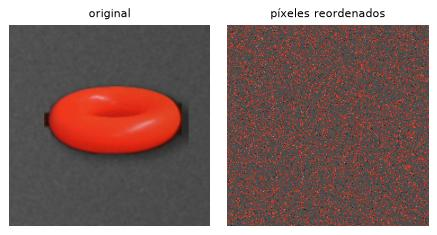

In [12]:
q = 'IMG_O1_Q'
arr = np.asarray(IMG224[q])
perm = np.random.default_rng(SEMILLA).permutation(224 * 224)
mezclada = Image.fromarray(arr.reshape(-1, 3)[perm].reshape(224, 224, 3))
h_orig, h_mez = hist_color(IMG224[q]), hist_color(mezclada)
print('diferencia máxima entre histogramas:', np.abs(h_orig - h_mez).max())
print('distancia coseno entre histogramas:', float(dist_coseno([h_orig], [h_mez])[0, 0]))
print('distancia coseno entre vectores de píxeles:', round(float(dist_coseno([PIX[q]], [desc_pixeles(mezclada)])[0, 0]), 4))
print('top 3 por histograma + coseno de la imagen mezclada:', top_k(dist_coseno([h_mez], matrices(HIST)[1])[0], base_img))

fig, ax = plt.subplots(1, 2, figsize=(5, 2.6))
ax[0].imshow(IMG224[q]); ax[0].set_title('original', fontsize=9)
ax[1].imshow(mezclada); ax[1].set_title('píxeles reordenados', fontsize=9)
for a in ax:
    a.axis('off')
plt.tight_layout(); plt.savefig(RES / 'ej2_mezclada.jpg', dpi=120, pil_kwargs={'quality': 88}); plt.show()

Reordené al azar los píxeles de IMG_O1_Q (semilla 0). El histograma no cambia en nada (diferencia máxima 0 y distancia coseno 0), así que la imagen mezclada recupera lo mismo que la original. El vector de píxeles, en cambio, queda a distancia coseno 0.1561. El histograma solo cuenta cuántos píxeles hay de cada color y pierde dónde está cada uno, o sea la forma y la posición del objeto. Para buscar el mismo objeto eso importa: un aro rojo y un morrón rojo pueden tener casi el mismo histograma, y un fondo grande pesa más en la cuenta que el objeto.

## Ejercicio 3. Imágenes con un extractor aprendido

Se busca mejorar la recuperación cuando cambian el fondo o la iluminación. Usar ResNet50 preentrenada con los pesos IMAGENET1K_V2 de la presentación, sin modificar los pesos ni utilizar la salida de clasificación.

a) Aplicar el preprocesamiento asociado a esos pesos directamente sobre la imagen RGB original. No alimentar el modelo con la versión aplanada ni agregar suavizado. Activar modo evaluación y deshabilitar el cálculo de gradientes.

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
entrada del modelo: (3, 224, 224)  media y desvío por canal: [ 0.58  -0.517 -0.875] [0.815 0.356 0.253]


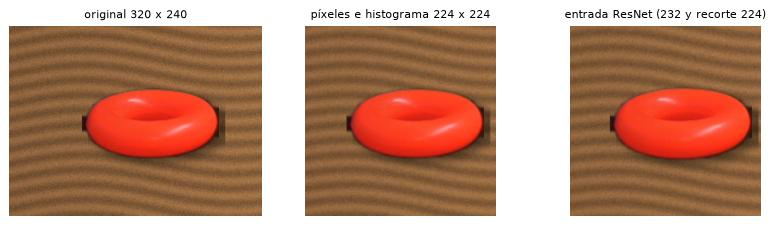

In [13]:
import torch
from torchvision.models import ResNet50_Weights, resnet50
from torchvision.models.feature_extraction import create_feature_extractor

PESOS = ResNet50_Weights.IMAGENET1K_V2
resnet = resnet50(weights=PESOS).eval()
for p in resnet.parameters():
    p.requires_grad_(False)
prep_resnet = PESOS.transforms()
extractor = create_feature_extractor(resnet, return_nodes={'layer2': 'layer2', 'layer4': 'layer4'})
print(prep_resnet)

x = prep_resnet(ORIGINALES['IMG_O1_B1'])
print('entrada del modelo:', tuple(x.shape), ' media y desvío por canal:', x.mean((1, 2)).numpy().round(3), x.std((1, 2)).numpy().round(3))
vista = (x.permute(1, 2, 0).numpy() * np.array(PESOS.transforms().std) + np.array(PESOS.transforms().mean)).clip(0, 1)
fig, ax = plt.subplots(1, 3, figsize=(9, 2.6))
ax[0].imshow(ORIGINALES['IMG_O1_B1']); ax[0].set_title('original 320 x 240', fontsize=9)
ax[1].imshow(IMG224['IMG_O1_B1']); ax[1].set_title('píxeles e histograma 224 x 224', fontsize=9)
ax[2].imshow(vista); ax[2].set_title('entrada ResNet (232 y recorte 224)', fontsize=9)
for a in ax:
    a.axis('off')
plt.tight_layout(); plt.savefig(RES / 'ej3_preprocesamiento.jpg', dpi=120, pil_kwargs={'quality': 88}); plt.show()

Uso `ResNet50_Weights.IMAGENET1K_V2.transforms()` sobre la foto original de 320 x 240: lleva el lado menor a 232, recorta el centro de 224 x 224, pasa a tensor en [0,1] y normaliza con la media y el desvío de ImageNet. No uso la versión aplanada ni agrego suavizado. El modelo está en `eval()`, los parámetros no calculan gradiente y la extracción corre dentro de `torch.inference_mode()`.

b) Extraer los mapas de layer2 y layer4. Para una imagen, registrar sus formas antes de reducirlos y explicar el significado de canales, alto y ancho. Aplicar promedio global espacial por canal y normalizar cada vector a norma L2: se obtienen 512 y 2048 componentes, respectivamente.

In [14]:
@torch.inference_mode()
def desc_resnet(im):
    mapas = extractor(prep_resnet(im).unsqueeze(0))
    l2 = mapas['layer2'].mean(dim=(2, 3))[0].numpy()  # promedio global espacial por canal
    l4 = mapas['layer4'].mean(dim=(2, 3))[0].numpy()
    return normalizar_l2(l2), normalizar_l2(l4), tuple(mapas['layer2'].shape), tuple(mapas['layer4'].shape)


_, _, forma2, forma4 = desc_resnet(ORIGINALES['IMG_O1_B1'])
print('forma de layer2 antes de reducir:', forma2, ' (lote, canales, alto, ancho)')
print('forma de layer4 antes de reducir:', forma4)

L2, L4 = {}, {}
for i in ids_img:
    L2[i], L4[i], _, _ = desc_resnet(ORIGINALES[i])
print('dimensiones:', L2[cons_img[0]].shape, L4[cons_img[0]].shape)
print('normas layer2:', round(min(np.linalg.norm(v) for v in L2.values()), 6), round(max(np.linalg.norm(v) for v in L2.values()), 6))
print('normas layer4:', round(min(np.linalg.norm(v) for v in L4.values()), 6), round(max(np.linalg.norm(v) for v in L4.values()), 6))
np.savez_compressed(CARAC / 'imagenes_resnet_layer2.npz', ids=np.array(ids_img), X=np.array([L2[i] for i in ids_img], dtype=np.float32))
np.savez_compressed(CARAC / 'imagenes_resnet_layer4.npz', ids=np.array(ids_img), X=np.array([L4[i] for i in ids_img], dtype=np.float32))

forma de layer2 antes de reducir: (1, 512, 28, 28)  (lote, canales, alto, ancho)
forma de layer4 antes de reducir: (1, 2048, 7, 7)


dimensiones: (512,) (2048,)
normas layer2: 1.0 1.0
normas layer4: 1.0 1.0


Para IMG_O1_B1, layer2 da (1, 512, 28, 28) y layer4 da (1, 2048, 7, 7). El 1 es el lote. Los canales son los filtros de la capa, cada uno responde a un patrón distinto: bordes y texturas en layer2, partes de objetos más abstractas en layer4. Alto y ancho son una grilla sobre la imagen, cada celda mira una zona (8 x 8 píxeles de la entrada en layer2 y 32 x 32 en layer4). El promedio global por canal deja vectores de 512 y 2048 componentes, todos con norma 1.

c) Construir un buscador separado para cada capa usando distancia coseno y obtener los top 3 de las seis consultas. Comparar con píxeles e histogramas mediante el protocolo del ejercicio 9. No comparar directamente un vector de layer2 con otro de layer4.

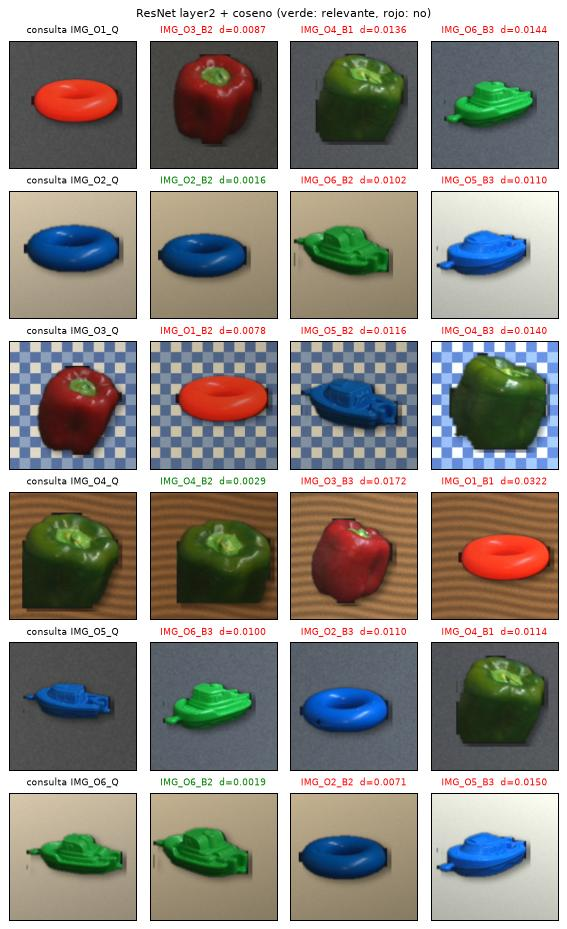

ResNet layer2 + coseno


consulta,top3,distancias,relevantes,P@3,R@3
IMG_O1_Q,"IMG_O3_B2, IMG_O4_B1, IMG_O6_B3","0.0087, 0.0136, 0.0144",0,0.0000,0.0000
IMG_O2_Q,"IMG_O2_B2, IMG_O6_B2, IMG_O5_B3","0.0016, 0.0102, 0.0110",1,0.3333,0.3333
IMG_O3_Q,"IMG_O1_B2, IMG_O5_B2, IMG_O4_B3","0.0078, 0.0116, 0.0140",0,0.0000,0.0000
IMG_O4_Q,"IMG_O4_B2, IMG_O3_B3, IMG_O1_B1","0.0029, 0.0172, 0.0322",1,0.3333,0.3333
IMG_O5_Q,"IMG_O6_B3, IMG_O2_B3, IMG_O4_B1","0.0100, 0.0110, 0.0114",0,0.0000,0.0000
IMG_O6_Q,"IMG_O6_B2, IMG_O2_B2, IMG_O5_B3","0.0019, 0.0071, 0.0150",1,0.3333,0.3333


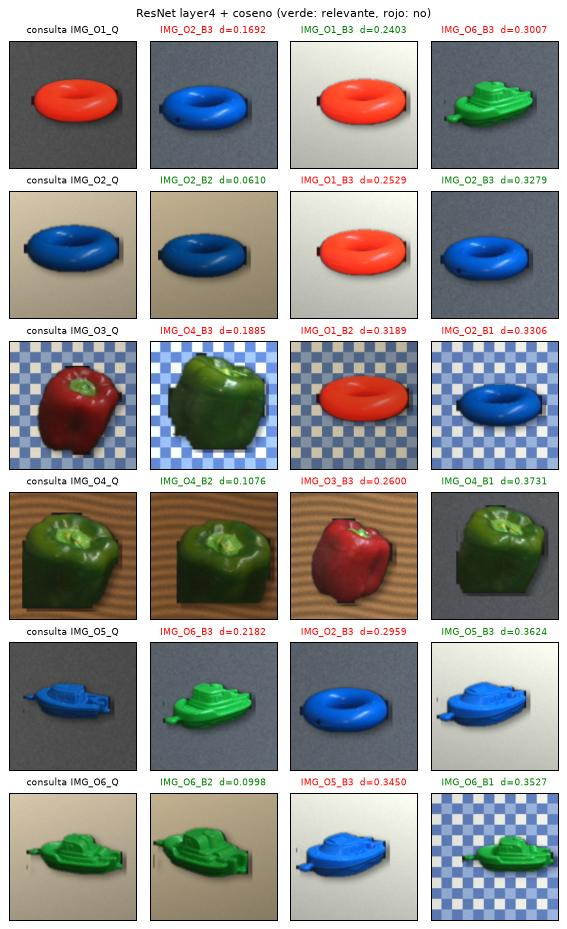

ResNet layer4 + coseno


consulta,top3,distancias,relevantes,P@3,R@3
IMG_O1_Q,"IMG_O2_B3, IMG_O1_B3, IMG_O6_B3","0.1692, 0.2403, 0.3007",1,0.3333,0.3333
IMG_O2_Q,"IMG_O2_B2, IMG_O1_B3, IMG_O2_B3","0.0610, 0.2529, 0.3279",2,0.6667,0.6667
IMG_O3_Q,"IMG_O4_B3, IMG_O1_B2, IMG_O2_B1","0.1885, 0.3189, 0.3306",0,0.0000,0.0000
IMG_O4_Q,"IMG_O4_B2, IMG_O3_B3, IMG_O4_B1","0.1076, 0.2600, 0.3731",2,0.6667,0.6667
IMG_O5_Q,"IMG_O6_B3, IMG_O2_B3, IMG_O5_B3","0.2182, 0.2959, 0.3624",1,0.3333,0.3333
IMG_O6_Q,"IMG_O6_B2, IMG_O5_B3, IMG_O6_B1","0.0998, 0.3450, 0.3527",2,0.6667,0.6667


In [15]:
for nombre, desc in [('ResNet layer2', L2), ('ResNet layer4', L4)]:
    Qm, Bm = matrices(desc)
    D = dist_coseno(Qm, Bm)
    rep = f'{nombre} + coseno'
    TABLAS_IMG[rep] = evaluar('imagen', rep, cons_img, base_img, D, RELEVANTES, explicar_img)
    grilla(rep, D, f"ej3_grilla_{nombre.split()[1]}.jpg")
    print(rep)
    display(mostrar(TABLAS_IMG[rep]))

In [16]:
resumen_img = pd.DataFrame([{'representación': r, 'P@3 media': t['P@3'].mean(), 'R@3 media': t['R@3'].mean(),
                             'aciertos (de 18)': int(t['relevantes'].sum())} for r, t in TABLAS_IMG.items()])
resumen_img.style.format({'P@3 media': '{:.4f}', 'R@3 media': '{:.4f}'}).hide(axis='index')

representación,P@3 media,R@3 media,aciertos (de 18)
píxeles + coseno,0.4444,0.4444,8
píxeles + euclidiana,0.4444,0.4444,8
histograma + coseno,0.2778,0.2778,5
histograma + euclidiana,0.2778,0.2778,5
ResNet layer2 + coseno,0.1667,0.1667,3
ResNet layer4 + coseno,0.4444,0.4444,8


layer4 llega a una P@3 media de 0.4444, igual que píxeles, y layer2 queda última con 0.1667. Pero fallan distinto. El error típico de layer4 es confundir objetos de la misma forma y distinto color: IMG_O1_Q (aro rojo) recupera primero IMG_O2_B3 (aro azul) y IMG_O3_Q (morrón rojo) recupera primero IMG_O4_B3 (morrón verde). layer4 describe qué tipo de objeto es más que su color. layer2 está más cerca de texturas y del fondo: casi todo lo que recupera comparte fondo con la consulta.

Un acierto: IMG_O4_Q (morrón verde sobre madera) con layer4 recupera IMG_O4_B2 a 0.1076 y en tercer lugar IMG_O4_B1, que está sobre el escritorio, o sea que reconoce el objeto aunque cambien el fondo y la luz. Un error: IMG_O3_Q (morrón rojo sobre el mantel) con layer4 no recupera ninguna foto relevante. Los tres resultados (morrón verde, aro rojo y aro azul) están sobre el mantel, cuya textura cuadriculada pesa tanto como el objeto.

d) Generar dos variantes de una consulta: una con menor brillo y otra con ruido suave de semilla fija. Mantener la base sin cambios. Comparar el ranking original y los dos nuevos rankings para cada descriptor y explicar qué cambios tolera mejor cada uno.

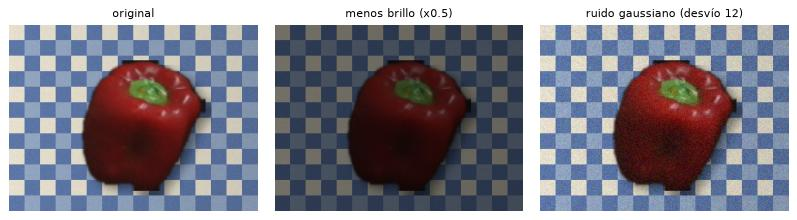

variante,representación,top3,distancias,relevantes en top 3,posiciones de los 3 relevantes
menos brillo (x0.5),ResNet layer2 + coseno,"IMG_O1_B2, IMG_O5_B2, IMG_O4_B3","0.0155, 0.0177, 0.0214",0,"6, 7, 16"
original,ResNet layer2 + coseno,"IMG_O1_B2, IMG_O5_B2, IMG_O4_B3","0.0078, 0.0116, 0.0140",0,"6, 7, 16"
ruido gaussiano (desvío 12),ResNet layer2 + coseno,"IMG_O1_B2, IMG_O4_B3, IMG_O5_B2","0.0230, 0.0253, 0.0267",0,"6, 7, 16"
menos brillo (x0.5),ResNet layer4 + coseno,"IMG_O4_B3, IMG_O1_B2, IMG_O3_B1","0.2093, 0.3377, 0.3615",1,"3, 7, 9"
original,ResNet layer4 + coseno,"IMG_O4_B3, IMG_O1_B2, IMG_O2_B1","0.1885, 0.3189, 0.3306",0,"5, 7, 9"
ruido gaussiano (desvío 12),ResNet layer4 + coseno,"IMG_O4_B3, IMG_O1_B2, IMG_O3_B1","0.2854, 0.3599, 0.3644",1,"3, 6, 7"
menos brillo (x0.5),histograma + coseno,"IMG_O3_B2, IMG_O4_B1, IMG_O6_B3","0.1199, 0.2920, 0.6287",1,"1, 7, 9"
original,histograma + coseno,"IMG_O5_B2, IMG_O1_B2, IMG_O3_B1","0.3287, 0.3498, 0.5007",1,"3, 8, 10"
ruido gaussiano (desvío 12),histograma + coseno,"IMG_O5_B2, IMG_O1_B2, IMG_O3_B1","0.3148, 0.3391, 0.5077",1,"3, 8, 10"
menos brillo (x0.5),píxeles + coseno,"IMG_O3_B1, IMG_O4_B3, IMG_O1_B2","0.0738, 0.0756, 0.0819",1,"1, 9, 13"


In [17]:
q = 'IMG_O3_Q'
VARIANTES = {
    'original': ORIGINALES[q],
    'menos brillo (x0.5)': ImageEnhance.Brightness(ORIGINALES[q]).enhance(0.5),
    'ruido gaussiano (desvío 12)': Image.fromarray(np.clip(np.asarray(ORIGINALES[q], dtype=np.float64)
                                                           + np.random.default_rng(SEMILLA).normal(0, 12, np.asarray(ORIGINALES[q]).shape), 0, 255).astype(np.uint8)),
}
fig, ax = plt.subplots(1, 3, figsize=(9, 2.4))
for a, (n, im) in zip(ax, VARIANTES.items()):
    a.imshow(im); a.set_title(n, fontsize=9); a.axis('off')
plt.tight_layout(); plt.savefig(RES / 'ej3_variantes.jpg', dpi=120, pil_kwargs={'quality': 88}); plt.show()

filas = []
for n, im in VARIANTES.items():
    i224 = a_224(im)
    l2, l4, _, _ = desc_resnet(im)
    for rep, vq, desc in [('píxeles + coseno', desc_pixeles(i224), PIX), ('histograma + coseno', hist_color(i224), HIST),
                          ('ResNet layer2 + coseno', l2, L2), ('ResNet layer4 + coseno', l4, L4)]:
        d = dist_coseno([vq], matrices(desc)[1])[0]
        top = top_k(d, base_img)
        rank = sorted(range(len(base_img)), key=lambda j: (round(float(d[j]), 10), base_img[j]))
        pos = [rank.index(base_img.index(r)) + 1 for r in RELEVANTES[q]]
        filas.append({'variante': n, 'representación': rep, 'top3': ', '.join(b for b, _ in top),
                      'distancias': ', '.join(f'{x:.4f}' for _, x in top), 'relevantes en top 3': sum(b in RELEVANTES[q] for b, _ in top),
                      'posiciones de los 3 relevantes': ', '.join(map(str, sorted(pos)))})
variantes = pd.DataFrame(filas).sort_values(['representación', 'variante'], kind='stable')
EXPERIMENTOS.extend(variantes.assign(modalidad='imagen', experimento='variantes de ' + q).to_dict('records'))
variantes.style.hide(axis='index')

Las variantes son de IMG_O3_Q (morrón rojo): una con el brillo a la mitad y otra con ruido gaussiano de desvío 12 (semilla 0). La base no cambia.

Píxeles con coseno no cambia el ranking en ninguna variante (los relevantes siguen en las posiciones 1, 9 y 13). Bajar el brillo multiplica todo el vector por un número y al normalizar ese factor desaparece, y el ruido suave se promedia entre 150528 coordenadas. Lo que no tolera es que el objeto cambie de lugar o de fondo.

El histograma tolera el ruido (posiciones 3, 8 y 10 igual que el original) pero no el brillo: con la imagen oscura los píxeles caen en otros colores de la paleta y el ranking cambia. Acá justo mejora (IMG_O3_B2, la foto de base con luz tenue, pasa al primer lugar), pero por parecerse en la luz y no en el objeto.

ResNet tolera las dos variantes. layer2 deja los relevantes en las mismas posiciones (6, 7 y 16) y layer4 casi no cambia (de 5, 7 y 9 pasa a 3, 7 y 9 con menos brillo y a 3, 6 y 7 con ruido), porque la red se entrenó con fotos en condiciones de luz y calidad muy variadas.

Evidencia a entregar: ejemplos antes y después del preprocesamiento, dimensiones, comprobaciones de normalización, grillas de resultados y análisis de al menos un acierto y un error. Los rankings de las variantes se analizan aparte de las seis consultas principales.

Las figuras de antes y después, las dimensiones, las normas y las grillas están en las celdas de arriba y en `datos/resultados`. El acierto y el error están analizados en el inciso c, y las variantes se guardan aparte en `ej9_experimentos.csv`.

## Ejercicio 4. Texto y decisiones de preprocesamiento

Un portal de soporte universitario busca respuestas a consultas escritas en español. Utilizar el corpus completo como base, conservando una copia literal de cada documento (ver ejercicio 1).

a) Construir una función de tokenización y normalización para la búsqueda léxica. Decidir minúsculas, Unicode, puntuación y stop words, conservar tildes, la negación y el término C++. Mostrar tokens antes y después para D07 y D09.

In [18]:
import nltk

nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

NEGACION = {'no', 'ni', 'sin', 'nunca', 'nada'}
STOP = set(stopwords.words('spanish')) - NEGACION
print('stop words usadas:', len(STOP), ' (lista de NLTK para español sin', sorted(NEGACION & set(stopwords.words('spanish'))), ')')


def tokenizar(texto):
    # Unicode NFC (las tildes quedan como un solo carácter), minúsculas y fuera la puntuación salvo en c++
    t = unicodedata.normalize('NFC', texto).lower()
    return re.findall(r'c\+\+|\w+', t)


def normalizar_tokens(texto):
    return [t for t in tokenizar(texto) if t not in STOP]


for d in ['D07', 'D09']:
    print(d, DOCS[d])
    print('   antes  :', DOCS[d].split())
    print('   después:', normalizar_tokens(DOCS[d]))

stop words usadas: 309  (lista de NLTK para español sin ['nada', 'ni', 'no', 'sin'] )
D07 El curso de C++ requiere conocimientos previos de programación.
   antes  : ['El', 'curso', 'de', 'C++', 'requiere', 'conocimientos', 'previos', 'de', 'programación.']
   después: ['curso', 'c++', 'requiere', 'conocimientos', 'previos', 'programación']
D09 El curso introductorio de Python no requiere conocimientos previos de programación.
   antes  : ['El', 'curso', 'introductorio', 'de', 'Python', 'no', 'requiere', 'conocimientos', 'previos', 'de', 'programación.']
   después: ['curso', 'introductorio', 'python', 'no', 'requiere', 'conocimientos', 'previos', 'programación']


Decisiones: paso el texto a Unicode NFC para que cada letra con tilde sea un solo carácter, y después a minúsculas. Las tildes se conservan. La puntuación se descarta porque la expresión regular solo toma palabras, salvo c++, que se toma completo antes que nada. Saco las stop words de la lista de NLTK para español, pero dejo afuera de esa lista las palabras de negación (no, ni, sin y nada), así que se conservan. Nunca no está en la lista, así que también queda. En D07 se van el, de y el punto, y C++ queda como c++. En D09 además queda el no.

b) Aplicar stemming o lematización a tres documentos, mostrando sus resultados. Comparar qué formas reúne cada técnica y elegir si se incorpora a la representación léxica. Registrar herramienta y recursos lingüísticos.

In [19]:
import spacy

stemmer = SnowballStemmer('spanish')
nlp = spacy.load('es_core_news_sm')
print('stemming: NLTK', nltk.__version__, 'SnowballStemmer("spanish")')
print('lematización: spaCy', spacy.__version__, 'modelo', nlp.meta['name'], nlp.meta['version'])


def lemas(texto):
    return {t.text.lower(): t.lemma_.lower() for t in nlp(texto) if not t.is_punct}


filas = []
for d in ['D02', 'D05', 'D10']:
    lm = lemas(DOCS[d])
    for t in normalizar_tokens(DOCS[d]):
        filas.append({'documento': d, 'token': t, 'stem (Snowball)': stemmer.stem(t), 'lema (spaCy)': lm.get(t, t)})
pd.DataFrame(filas).to_csv(RES / 'ej4_stem_lema.csv', index=False)
pd.DataFrame(filas).style.hide(axis='index')

stemming: NLTK 3.10.4 SnowballStemmer("spanish")
lematización: spaCy 3.8.18 modelo core_news_sm 3.8.0


documento,token,stem (Snowball),lema (spaCy)
D02,si,si,si
D02,no,no,no
D02,recordás,recordas,recordás
D02,clave,clav,clave
D02,solicitá,solicit,solicitar
D02,enlace,enlac,enlace
D02,recuperación,recuper,recuperación
D02,correo,corre,correo
D02,electrónico,electron,electrónico
D05,préstamo,prestam,préstamo


In [20]:
# qué formas del corpus y las consultas reúne cada técnica
todos = {**DOCS, **CONSULTAS_TEXTO}
formas = sorted({t for txt in todos.values() for t in normalizar_tokens(txt)})
lema_de = {}
for txt in todos.values():
    lema_de.update(lemas(txt))
grupos_stem, grupos_lema = {}, {}
for f in formas:
    grupos_stem.setdefault(stemmer.stem(f), set()).add(f)
    grupos_lema.setdefault(lema_de.get(f, f), set()).add(f)
print('Stemming reúne:')
for k, v in sorted(grupos_stem.items()):
    if len(v) > 1:
        print(f'   {k}: {sorted(v)}')
print('Lematización reúne:')
for k, v in sorted(grupos_lema.items()):
    if len(v) > 1:
        print(f'   {k}: {sorted(v)}')


def preprocesar(texto):
    # representación léxica elegida: tokens normalizados + stemming de Snowball
    return [stemmer.stem(t) for t in normalizar_tokens(texto)]


print('\nD07 ->', preprocesar(DOCS['D07']))
print('Q4  ->', preprocesar(CONSULTAS_TEXTO['Q4']))

Stemming reúne:
   bec: ['beca', 'becas']
   conoc: ['conocida', 'conocimientos']
   curs: ['cursar', 'curso']
   libr: ['libro', 'libros']
   olvid: ['olvidada', 'olvidé']
   program: ['programación', 'programar', 'programaron', 'programé']
   pued: ['puede', 'pueden', 'puedo']
   recuper: ['recuperación', 'recuperar', 'recupero']
Lematización reúne:
   beca: ['beca', 'becas']
   libro: ['libro', 'libros']
   poder: ['puede', 'pueden', 'puedo']
   programar: ['programar', 'programaron']
   recuperar: ['recuperar', 'recupero']

D07 -> ['curs', 'c++', 'requier', 'conoc', 'previ', 'program']
Q4  -> ['pued', 'curs', 'c++', 'sin', 'sab', 'program']


Elijo stemming. Reúne más formas útiles para estas consultas: programé, programaron, programar y programación quedan en program, que es lo que une Q5 con D09 y D10, y recupero, recuperar y recuperación quedan en recuper, que une Q1 con D01 y D02. La lematización de spaCy no junta programación con programar ni recuperación con recuperar, porque para el diccionario son palabras distintas, y además falla con el voseo y con algunas formas: deja recordás sin cambiar, convierte renovarse en "renovar él" y lematiza dura como duro.

El stemming también tiene costos. Junta conocida con conocimientos en conoc, que no tienen relación, y no une recuerdo con recordás porque el verbo cambia la raíz. Además Snowball saca las tildes al recortar (días queda dias), pero como se aplica igual a base y consultas no cambia las coincidencias.

Herramientas: NLTK 3.10.4 con `SnowballStemmer('spanish')` y su lista de stop words en español, y spaCy 3.8.18 con el modelo `es_core_news_sm` 3.8.0 para los lemas.

c) Explicar cómo una limpieza que elimina "no" o los signos "++" puede cambiar la búsqueda. Aclarar por qué D07 y D08 son relevantes para Q4 aunque la respuesta a la posibilidad planteada sea negativa.

In [21]:
def limpieza_agresiva(texto):
    # stop words completas de NLTK (incluye "no") y sin ningún signo
    return [stemmer.stem(t) for t in re.findall(r'\w+', texto.lower()) if t not in set(stopwords.words('spanish'))]


for i in ['D07', 'D09', 'Q4']:
    print(i, ' elegida:', preprocesar(todos[i]), '   agresiva:', limpieza_agresiva(todos[i]))

D07  elegida: ['curs', 'c++', 'requier', 'conoc', 'previ', 'program']    agresiva: ['curs', 'c', 'requier', 'conoc', 'previ', 'program']
D09  elegida: ['curs', 'introductori', 'python', 'no', 'requier', 'conoc', 'previ', 'program']    agresiva: ['curs', 'introductori', 'python', 'requier', 'conoc', 'previ', 'program']
Q4  elegida: ['pued', 'curs', 'c++', 'sin', 'sab', 'program']    agresiva: ['pued', 'curs', 'c', 'sab', 'program']


Si la limpieza saca el no, D09 ("no requiere conocimientos previos") queda con los mismos términos que D07 ("requiere conocimientos previos") más introductorio y Python, y el buscador ya no distingue un curso que pide saber programar de uno que no. Si saca los signos, C++ queda como c, una letra suelta que también podría venir de C o C#, y Q4 pierde su término más específico. Con la limpieza elegida c++ es un término propio que solo aparece en D07, D08 y Q4.

D07 y D08 son relevantes para Q4 porque contestan la pregunta: dicen que para C++ hay que saber programar. Que la respuesta sea "no, no podés" no la hace menos útil. La relevancia es si el documento responde lo que se pregunta, no si la respuesta es afirmativa.

## Ejercicio 5. Bolsa de palabras y TF IDF

El objetivo es construir vectores interpretables para el portal y observar cómo la frecuencia y la rareza de las palabras afectan el ranking. Usar la misma función de preprocesamiento del ejercicio 4 en base y consultas.

$$idf(t) = \ln\left(\frac{1 + N}{1 + df(t)}\right) + 1 \qquad w(t, d) = tf(t, d) \times idf(t)$$

N es la cantidad de documentos de la base, df(t) la cantidad de documentos que contienen t y tf(t,d) sus apariciones en d. El experimento de repetición se evalúa aparte y no modifica la base principal.

a) Construir el vocabulario solamente con D01 a D12 y fijar un orden. Generar una matriz de bolsa de palabras con frecuencias crudas. Mostrar el vocabulario, la dimensión y el vector de un documento, identificando sus coordenadas no nulas.

In [22]:
TOK_DOCS = {d: preprocesar(t) for d, t in DOCS.items()}
VOCAB = sorted({t for toks in TOK_DOCS.values() for t in toks})  # orden alfabético fijo
IDX = {t: i for i, t in enumerate(VOCAB)}
print('dimensión del vocabulario:', len(VOCAB))
print(VOCAB)


def bolsa(tokens):
    v = np.zeros(len(VOCAB))
    for t in tokens:
        if t in IDX:  # las palabras fuera del vocabulario se ignoran
            v[IDX[t]] += 1
    return v


X_BOW = np.array([bolsa(TOK_DOCS[d]) for d in base_txt])
print('matriz de bolsa de palabras:', X_BOW.shape)
d = 'D04'
nz = np.nonzero(X_BOW[base_txt.index(d)])[0]
print(f'{d} coordenadas no nulas:', {f'{i} ({VOCAB[i]})': int(X_BOW[base_txt.index(d), i]) for i in nz})

dimensión del vocabulario: 62
['abre', 'acces', 'asist', 'ayud', 'bec', 'bibliotec', 'c++', 'cambi', 'clas', 'clav', 'colect', 'complet', 'conoc', 'contraseñ', 'corre', 'cubr', 'curs', 'destin', 'dias', 'domicili', 'dur', 'econom', 'electron', 'eleg', 'enlac', 'formulari', 'ingres', 'inicial', 'inscrib', 'introductori', 'lectur', 'libr', 'lun', 'necesari', 'no', 'nunc', 'olvid', 'opcion', 'ped', 'perfil', 'person', 'prest', 'prestam', 'previ', 'program', 'pued', 'python', 'recordas', 'recuper', 'renov', 'requier', 'restablec', 'sab', 'sal', 'segur', 'seman', 'si', 'siet', 'solicit', 'transport', 'viaj', 'viern']
matriz de bolsa de palabras: (12, 62)
D04 coordenadas no nulas: {'5 (bibliotec)': 1, '18 (dias)': 1, '19 (domicili)': 1, '31 (libr)': 1, '41 (prest)': 1, '57 (siet)': 1}


El vocabulario se arma solo con D01 a D12, después del preprocesamiento del ejercicio 4, y queda en orden alfabético: 62 términos, así que la matriz es de 12 x 62. D04 tiene 6 coordenadas no nulas, todas con frecuencia 1: 5 (bibliotec), 18 (dias), 19 (domicili), 31 (libr), 41 (prest) y 57 (siet). La, a y durante se fueron como stop words.

b) Construir TF-IDF con frecuencia cruda e IDF suavizada según la fórmula. Normalizar cada vector a norma L2. Mostrar el cálculo manual del peso del término "biblioteca" (o su forma normalizada) en D04, antes de normalizar, y comprobarlo con el programa. En el corpus aparece en 3 de los 12 documentos.

In [23]:
N = len(base_txt)
DF = (X_BOW > 0).sum(axis=0)
IDF = np.log((1 + N) / (1 + DF)) + 1
pd.DataFrame({'termino': VOCAB, 'df': DF, 'idf': IDF}).to_csv(CARAC / 'texto_vocabulario_idf.csv', index=False)


def tfidf(tokens, normalizar=True):
    w = bolsa(tokens) * IDF
    return normalizar_l2(w) if normalizar else w


X_TFIDF = np.array([tfidf(TOK_DOCS[d]) for d in base_txt])

t = stemmer.stem('biblioteca')
j = IDX[t]
tf = X_BOW[base_txt.index('D04'), j]
print(f'término normalizado: {t}  tf = {tf:.0f}  df = {DF[j]}  N = {N}')
print(f'manual: idf = ln((1 + 12) / (1 + 3)) + 1 = ln(3.25) + 1 = {np.log(13 / 4) + 1:.4f}  ->  w = 1 x {np.log(13 / 4) + 1:.4f}')
print(f'programa, antes de normalizar: {tfidf(TOK_DOCS["D04"], normalizar=False)[j]:.4f}')
print(f'programa, después de normalizar: {X_TFIDF[base_txt.index("D04"), j]:.4f}')

# control con scikit-learn, que usa la misma fórmula de IDF suavizada
from sklearn.feature_extraction.text import TfidfVectorizer

sk = TfidfVectorizer(analyzer=preprocesar, smooth_idf=True, norm='l2').fit([DOCS[d] for d in base_txt])
assert list(sk.get_feature_names_out()) == VOCAB
print('coincide con scikit-learn:', np.allclose(sk.transform([DOCS[d] for d in base_txt]).toarray(), X_TFIDF))
print('normas de los documentos:', np.linalg.norm(X_TFIDF, axis=1).round(6).tolist())

término normalizado: bibliotec  tf = 1  df = 3  N = 12
manual: idf = ln((1 + 12) / (1 + 3)) + 1 = ln(3.25) + 1 = 2.1787  ->  w = 1 x 2.1787
programa, antes de normalizar: 2.1787
programa, después de normalizar: 0.3291
coincide con scikit-learn: True
normas de los documentos: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


Cálculo manual para biblioteca (bibliotec) en D04: tf = 1, df = 3 y N = 12. idf = ln((1 + 12) / (1 + 3)) + 1 = ln(3.25) + 1 = 1.1787 + 1 = 2.1787. Entonces w = 1 x 2.1787 = 2.1787 antes de normalizar, que es lo mismo que da el programa. Después de normalizar D04 a norma 1 queda en 0.3291. Como control, la matriz coincide con la de `TfidfVectorizer` de scikit-learn, que usa la misma IDF suavizada.

c) Transformar las seis consultas usando el vocabulario y los IDF guardados. Obtener top 3 por distancia coseno para bolsa de palabras y TF-IDF. Mostrar los puntajes y calcular las métricas del ejercicio 9.

In [24]:
TOK_CONS = {q: preprocesar(t) for q, t in CONSULTAS_TEXTO.items()}
for q in cons_txt:
    print(q, TOK_CONS[q], ' fuera del vocabulario:', [t for t in TOK_CONS[q] if t not in IDX])

Q_BOW = np.array([bolsa(TOK_CONS[q]) for q in cons_txt])
Q_TFIDF = np.array([tfidf(TOK_CONS[q]) for q in cons_txt])
TABLAS_TXT = {}
TABLAS_TXT['bolsa de palabras + coseno'] = evaluar('texto', 'bolsa de palabras + coseno', cons_txt, base_txt,
                                                   dist_coseno(Q_BOW, X_BOW), RELEVANTES, explicar_txt)
TABLAS_TXT['TF-IDF + coseno'] = evaluar('texto', 'TF-IDF + coseno', cons_txt, base_txt,
                                        dist_coseno(Q_TFIDF, X_TFIDF), RELEVANTES, explicar_txt)
for rep, t in TABLAS_TXT.items():
    print(rep)
    display(mostrar(t))

Q1 ['olvid', 'contraseñ', 'com', 'recuper', 'acces']  fuera del vocabulario: ['com']
Q2 ['no', 'recuerd', 'clav', 'pued', 'envi', 'enlac']  fuera del vocabulario: ['recuerd', 'envi']
Q3 ['cuant', 'dias', 'pued', 'llev', 'libr', 'cas']  fuera del vocabulario: ['cuant', 'llev', 'cas']
Q4 ['pued', 'curs', 'c++', 'sin', 'sab', 'program']  fuera del vocabulario: ['sin']
Q5 ['nunc', 'program', 'curs', 'empez', 'python']  fuera del vocabulario: ['empez']
Q6 ['ayud', 'pag', 'colect', 'facult']  fuera del vocabulario: ['pag', 'facult']
bolsa de palabras + coseno


consulta,top3,distancias,relevantes,P@3,R@3
Q1,"D01, D03, D02","0.2929, 0.8110, 0.8333",2,0.6667,1.0000
Q2,"D02, D05, D09","0.5000, 0.8110, 0.8232",1,0.3333,0.5000
Q3,"D04, D05, D01","0.5286, 0.5636, 1.0000",2,0.6667,1.0000
Q4,"D08, D07, D09","0.4000, 0.4523, 0.6838",2,0.6667,1.0000
Q5,"D10, D09, D07","0.3876, 0.4697, 0.5918",2,0.6667,1.0000
Q6,"D11, D12, D01","0.7327, 0.7327, 1.0000",2,0.6667,1.0000


TF-IDF + coseno


consulta,top3,distancias,relevantes,P@3,R@3
Q1,"D01, D03, D02","0.2929, 0.8392, 0.8619",2,0.6667,1.0000
Q2,"D02, D05, D09","0.5059, 0.7941, 0.8406",1,0.3333,0.5000
Q3,"D04, D05, D01","0.5444, 0.5820, 1.0000",2,0.6667,1.0000
Q4,"D08, D07, D09","0.4589, 0.5109, 0.7471",2,0.6667,1.0000
Q5,"D10, D09, D07","0.4370, 0.5274, 0.6492",2,0.6667,1.0000
Q6,"D11, D12, D01","0.7221, 0.7221, 1.0000",2,0.6667,1.0000


Las consultas se transforman con el vocabulario y los IDF guardados, y los términos que no están en el vocabulario se ignoran. Bolsa de palabras y TF-IDF devuelven el mismo top 3 en las seis consultas, con P@3 media 0.6111 y R@3 media 0.9167. Cinco consultas recuperan sus dos relevantes. La que falla es Q2: recuerdo y recordás dan raíces distintas (recuerd y recordas), así que D01 no comparte ningún término con Q2, y en cambio entran D05 por pued y D09 por no. En Q6, D11 y D12 empatan a 0.7221 porque cada uno comparte un solo término con el mismo IDF (colect y ayud) y el empate se resuelve por ID. El tercer resultado de Q3 y Q6 es D01 a distancia 1, o sea que no comparte nada con la consulta y aparece solo por completar el top 3.

TF-IDF cambia los puntajes pero no el orden, porque en este corpus casi todos los términos aparecen en uno o dos documentos y tienen IDF parecidos.

d) Procesar además la consulta "xilófono submarino". Mostrar qué ocurre si ningún término pertenece al vocabulario. Devolver un estado explícito de consulta sin términos conocidos, sin presentar vecinos arbitrarios como respuestas útiles.

In [25]:
def buscar_texto(consulta, k=3):
    toks = preprocesar(consulta)
    v = tfidf(toks)
    if np.linalg.norm(v) == 0:
        return {'estado': 'consulta sin términos conocidos', 'tokens': toks, 'resultados': []}
    return {'estado': 'ok', 'tokens': toks, 'resultados': top_k(dist_coseno([v], X_TFIDF)[0], base_txt, k)}


r = buscar_texto('xilófono submarino')
print(r)
print('vector de la consulta: norma =', np.linalg.norm(tfidf(r['tokens'])), ' distancias =', dist_coseno([tfidf(r['tokens'])], X_TFIDF)[0][:3], '...')
EXPERIMENTOS.append({'modalidad': 'texto', 'experimento': 'consulta xilófono submarino', 'representación': 'TF-IDF + coseno',
                     'top3': r['estado'], 'relevantes en top 3': 0})

{'estado': 'consulta sin términos conocidos', 'tokens': ['xilofon', 'submarin'], 'resultados': []}
vector de la consulta: norma = 0.0  distancias = [nan nan nan] ...


Xilófono submarino queda como xilofon y submarin, y ninguno está en el vocabulario. El vector de la consulta es todo ceros, su norma es 0 y el coseno no se puede calcular (da una división por cero, NaN). Si se ordenara igual, aparecerían documentos cualquiera por el desempate de ID. Por eso la función devuelve el estado "consulta sin términos conocidos" y una lista vacía de resultados.

e) En una copia de D04, repetir diez veces la palabra "biblioteca". Comparar el vector y su posición para Q3 manteniendo congelados vocabulario e IDF. Explicar por qué aumentar una frecuencia no necesariamente mejora la calidad de la respuesta.

In [26]:
D04_REP = DOCS['D04'].replace('biblioteca', ' '.join(['biblioteca'] * 10))
print('copia:', D04_REP)
v_orig, v_rep = X_TFIDF[base_txt.index('D04')], tfidf(preprocesar(D04_REP))
pd.set_option('display.float_format', '{:.4f}'.format)
rep_d04 = pd.DataFrame({'D04': v_orig, 'D04 con repetición': v_rep}, index=VOCAB).loc[lambda x: (x != 0).any(axis=1)]
rep_d04.rename_axis('termino').to_csv(RES / 'ej5_repeticion_d04.csv')
display(rep_d04)

q3 = Q_TFIDF[cons_txt.index('Q3')]
for nombre, X in [('base original', X_TFIDF), ('base con la copia en lugar de D04', np.where(np.array(base_txt)[:, None] == 'D04', v_rep, X_TFIDF))]:
    d = dist_coseno([q3], X)[0]
    rank = sorted(range(N), key=lambda j: (round(float(d[j]), 10), base_txt[j]))
    print(f'{nombre}: d(Q3, D04) = {d[3]:.4f}, posición de D04 = {rank.index(3) + 1}, top 3 = {top_k(d, base_txt)}')
    EXPERIMENTOS.append({'modalidad': 'texto', 'experimento': 'repetición de biblioteca en D04', 'representación': 'TF-IDF + coseno',
                         'variante': nombre, 'top3': ', '.join(b for b, _ in top_k(d, base_txt)),
                         'relevantes en top 3': sum(b in REL_TEXTO['Q3'] for b, _ in top_k(d, base_txt)),
                         'posición de D04': rank.index(3) + 1})

copia: La biblioteca biblioteca biblioteca biblioteca biblioteca biblioteca biblioteca biblioteca biblioteca biblioteca presta libros a domicilio durante siete días.


,D04,D04 con repetición
bibliotec,0.3291,0.9612
dias,0.4338,0.1267
domicili,0.4338,0.1267
libr,0.3726,0.1088
prest,0.4338,0.1267
siet,0.4338,0.1267


base original: d(Q3, D04) = 0.5444, posición de D04 = 1, top 3 = [('D04', 0.5443996314510134), ('D05', 0.5820381478072695), ('D01', 1.0)]
base con la copia en lugar de D04: d(Q3, D04) = 0.8669, posición de D04 = 2, top 3 = [('D05', 0.5820381478072695), ('D04', 0.8669403209657864), ('D01', 1.0)]


Con biblioteca diez veces, tf pasa de 1 a 10 y el peso normalizado de bibliotec sube de 0.3291 a 0.9612. Como el vector sigue teniendo norma 1, los demás términos bajan (dias, domicili, prest y siet de 0.4338 a 0.1267, y libr de 0.3726 a 0.1088). Q3 no dice biblioteca, coincide con D04 en días y libro, y esos son justo los términos que perdieron peso. La distancia de Q3 a D04 sube de 0.5444 a 0.8669 y D04 baja del primer al segundo lugar, detrás de D05. Repetir una palabra no agrega información, solo hace que el vector apunte casi todo hacia esa palabra, y el documento termina respondiendo peor a consultas que no la usan.

## Ejercicio 6. Embeddings de texto y paráfrasis

Utilizar el modo denso de BGE-M3 presentado en clase, con pesos congelados. Se pretende recuperar respuestas aunque la consulta use expresiones diferentes de las del documento.

a) Codificar los textos originales, sin aplicar automáticamente la eliminación de stop words ni el stemming del buscador léxico. Usar el tokenizer y la receta del modelo. Obtener un vector por documento y consulta, normalizarlo a norma L2 y verificar su dimensión de 1024.

In [27]:
from transformers import AutoModel, AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
tok_bge = AutoTokenizer.from_pretrained('BAAI/bge-m3')
bge = AutoModel.from_pretrained('BAAI/bge-m3', use_safetensors=False).eval()


@torch.inference_mode()
def emb_bge(texto):
    # receta del modo denso de BGE-M3: estado oculto del token [CLS] de la última capa, normalizado a L2
    enc = tok_bge(texto, truncation=True, max_length=8192, return_tensors='pt')
    v = bge(**enc).last_hidden_state[0, 0].numpy()
    return normalizar_l2(v)


print('tokens de D07:', tok_bge.convert_ids_to_tokens(tok_bge(DOCS['D07'])['input_ids']))
E_DOCS = np.array([emb_bge(DOCS[d]) for d in base_txt])
E_CONS = np.array([emb_bge(CONSULTAS_TEXTO[q]) for q in cons_txt])
print('dimensión:', E_DOCS.shape[1], ' normas:', np.linalg.norm(np.vstack([E_DOCS, E_CONS]), axis=1).min().round(6),
      np.linalg.norm(np.vstack([E_DOCS, E_CONS]), axis=1).max().round(6))
np.savez_compressed(CARAC / 'texto_bge_m3.npz', ids=np.array(base_txt + cons_txt), X=np.vstack([E_DOCS, E_CONS]).astype(np.float32))

tokens de D07: ['<s>', '▁El', '▁curso', '▁de', '▁C', '++', '▁requiere', '▁conocimientos', '▁previo', 's', '▁de', '▁programación', '.', '</s>']


dimensión: 1024  normas: 1.0 1.0


Uso el tokenizer y el modelo de BAAI/bge-m3 con transformers. La receta del modo denso es tomar el estado oculto del primer token (`<s>`, que hace de CLS) en la última capa y normalizarlo a L2. Los textos entran tal cual, con mayúsculas, tildes, puntuación y stop words, y el tokenizer los parte en subpalabras (C++ queda como ▁C y ++). Cada documento y cada consulta dan un vector de 1024 con norma 1.

b) Recuperar el top 3 por coseno para las mismas seis consultas. Comparar con TF-IDF: identificar una paráfrasis, una consulta con un término específico y un caso con negación. Explicar resultados observados sin asumir que el modelo aprendido siempre será superior.

In [28]:
D_BGE = dist_coseno(E_CONS, E_DOCS)
TABLAS_TXT['BGE-M3 denso + coseno'] = evaluar('texto', 'BGE-M3 denso + coseno', cons_txt, base_txt, D_BGE, RELEVANTES, explicar_txt)
comp = TABLAS_TXT['TF-IDF + coseno'][['consulta', 'top3', 'distancias', 'relevantes']].merge(
    TABLAS_TXT['BGE-M3 denso + coseno'][['consulta', 'top3', 'distancias', 'relevantes']], on='consulta', suffixes=(' TF-IDF', ' BGE-M3'))
comp.to_csv(RES / 'ej6_tfidf_vs_bge.csv', index=False)
comp.style.hide(axis='index')

consulta,top3 TF-IDF,distancias TF-IDF,relevantes TF-IDF,top3 BGE-M3,distancias BGE-M3,relevantes BGE-M3
Q1,"D01, D03, D02","0.2929, 0.8392, 0.8619",2,"D02, D01, D03","0.2256, 0.2264, 0.2927",2
Q2,"D02, D05, D09","0.5059, 0.7941, 0.8406",1,"D02, D01, D03","0.1821, 0.3752, 0.4113",2
Q3,"D04, D05, D01","0.5444, 0.5820, 1.0000",2,"D04, D05, D06","0.2739, 0.3584, 0.4920",2
Q4,"D08, D07, D09","0.4589, 0.5109, 0.7471",2,"D08, D07, D09","0.2570, 0.3062, 0.4746",2
Q5,"D10, D09, D07","0.4370, 0.5274, 0.6492",2,"D10, D09, D07","0.2470, 0.2500, 0.4776",2
Q6,"D11, D12, D01","0.7221, 0.7221, 1.0000",2,"D11, D12, D04","0.3527, 0.4387, 0.5767",2


BGE-M3 recupera los dos relevantes en las seis consultas (P@3 media 0.6667 y R@3 media 1, que es el máximo posible en texto).

Paráfrasis: Q2 ("No recuerdo mi clave. ¿Me pueden enviar un enlace?"). TF-IDF solo encuentra D02 y no ve D01, que habla de "contraseña olvidada" y "Recuperar acceso" sin usar ninguna palabra de la consulta. BGE-M3 pone D02 primero y D01 segundo, porque en su espacio olvidar la clave y recuperar el acceso quedan cerca.

Término específico: Q4 (C++). Los dos buscadores devuelven D08 y D07 primero. En TF-IDF lo decide c++, que solo está en esos dos documentos y tiene IDF alto. BGE-M3 parte C++ en subpalabras y llega igual al mismo resultado. Acá no hay diferencia, y el léxico gana en costo y en que se puede explicar término por término.

Negación: Q5 ("Nunca programé") frente a D09 ("no requiere conocimientos previos") y D07 ("requiere conocimientos previos"), que solo se diferencian por el no. Los dos ponen D09 antes que D07, pero en TF-IDF la diferencia viene de que D09 dice Python y no del no, porque Q5 dice nunca y no comparte esa palabra. BGE-M3 separa más los dos documentos (0.2500 contra 0.4776). En Q4 el sin queda fuera del vocabulario y TF-IDF lo ignora.

No asumo que el modelo aprendido sea siempre mejor. En 5 de las 6 consultas TF-IDF ya encuentra los mismos documentos, BGE-M3 necesita un modelo de más de 2 GB y tarda bastante más por consulta (ejercicio 9), y sus distancias son menos claras: en Q1, D03 (cambiar una contraseña que se conoce) queda a 0.2927, casi tan cerca como los relevantes (0.2256 y 0.2264). En un corpus más grande un documento parecido pero que no responde podría pasar adelante.

c) Si los documentos fueran extensos, proponer fragmentos de 512 tokens con solape de 64. Calcular el avance entre fragmentos y definir qué metadatos conservar para recuperar documento y posición. Explicar por qué no deben contarse los fragmentos repetidos como respuestas independientes al evaluar documentos.

In [29]:
LARGO, SOLAPE = 512, 64
AVANCE = LARGO - SOLAPE
print('avance entre fragmentos =', LARGO, '-', SOLAPE, '=', AVANCE, 'tokens')


def fragmentar(doc_id, texto):
    enc = tok_bge(texto, add_special_tokens=False, return_offsets_mapping=True)
    ids, offs = enc['input_ids'], enc['offset_mapping']
    frags, ini = [], 0
    while True:
        fin = min(ini + LARGO, len(ids))
        frags.append({'doc_id': doc_id, 'fragmento': len(frags), 'token_inicio': ini, 'token_fin': fin,
                      'caracter_inicio': offs[ini][0], 'caracter_fin': offs[fin - 1][1]})
        if fin == len(ids):
            return pd.DataFrame(frags)
        ini += AVANCE


# documento largo de ejemplo: el corpus completo repetido ocho veces
largo = ' '.join([DOCS[d] for d in base_txt] * 8)
print('tokens del documento de ejemplo:', len(tok_bge(largo, add_special_tokens=False)['input_ids']))
fragmentos = fragmentar('DOC_LARGO', largo)
fragmentos.to_csv(RES / 'ej6_fragmentos.csv', index=False)
fragmentos.style.hide(axis='index')

avance entre fragmentos = 512 - 64 = 448 tokens
tokens del documento de ejemplo: 1400


doc_id,fragmento,token_inicio,token_fin,caracter_inicio,caracter_fin
DOC_LARGO,0,0,512,0,2528
DOC_LARGO,1,448,960,2191,4727
DOC_LARGO,2,896,1400,4411,6911


El avance es 512 - 64 = 448 tokens: el fragmento k empieza en el token 448 k y termina en el mínimo entre 448 k + 512 y el largo del documento, así que cada fragmento repite los últimos 64 tokens del anterior. Un documento de L tokens (L mayor que 512) da 1 + techo((L - 512) / 448) fragmentos. En el ejemplo, el corpus repetido ocho veces tiene 1400 tokens y queda en 3 fragmentos: del token 0 al 512, del 448 al 960 y del 896 al 1400.

Metadatos a guardar por fragmento: ID del documento, número de fragmento, token de inicio y de fin, y carácter de inicio y de fin en el texto original. Con eso se vuelve al documento y se puede mostrar el pasaje exacto.

Al evaluar documentos, varios fragmentos del mismo documento son una sola respuesta. Si se contaran por separado, una consulta que trae tres fragmentos del mismo documento relevante tendría P@3 = 1 con un solo documento encontrado, y el top 3 quedaría ocupado por repeticiones en lugar de otros documentos. Hay que agrupar por ID de documento, quedarse con la mejor distancia de cada uno y recién ahí armar el top 3.

## Ejercicio 7. Sonido con MFCC y orden temporal

Un archivo de grabaciones permite buscar otra pronunciación de la misma frase. El interés está en el contenido hablado, no en identificar al hablante ni en reconocer una copia exacta del archivo. Se evaluará hasta dónde alcanzan descriptores acústicos para esa tarea.

| ID de frase | Contenido |
|---|---|
| F1 | La biblioteca abre por la mañana. |
| F2 | La biblioteca cierra por la mañana. |
| F3 | El laboratorio abre por la tarde. |
| F4 | El laboratorio cierra por la tarde. |

Grabar tres repeticiones independientes por frase para la base y una cuarta para consulta. Las consultas se pronuncian un poco más lentamente. Usar un mismo hablante, micrófono y ambiente en esta primera experiencia, incluir un breve silencio inicial y final. No generar las consultas copiando o editando un archivo de la base.

a) Inspeccionar tasa de muestreo, canales, cantidad de muestras, duración y amplitud máxima. Convertir a mono y remuestrear a 16 kHz con filtrado antialias. Verificar que duración ≈ cantidad de muestras / 16000.

In [30]:
import librosa
import librosa.display
import soundfile as sf

SR = 16000
ids_son = base_son + cons_son
filas, MONO16 = [], {}
for i in ids_son:
    y, sr = sf.read(ORIG / 'sonido' / f'{i}.wav', always_2d=True)
    info = sf.info(ORIG / 'sonido' / f'{i}.wav')
    mono = y.mean(axis=1)
    # soxr_hq: remuestreo con filtro pasabajos antialias
    y16 = librosa.resample(mono, orig_sr=sr, target_sr=SR, res_type='soxr_hq')
    MONO16[i] = y16
    filas.append({'id': i, 'tasa (Hz)': sr, 'canales': info.channels, 'muestras': len(y), 'duración (s)': round(info.duration, 4),
                  'amplitud máx.': round(float(np.abs(y).max()), 4), 'muestras 16 kHz': len(y16),
                  'muestras / 16000': round(len(y16) / SR, 4)})
inspeccion = pd.DataFrame(filas)
print('máxima diferencia entre duración original y muestras / 16000:',
      round(float((inspeccion['duración (s)'] - inspeccion['muestras / 16000']).abs().max()), 6), 's')
inspeccion.to_csv(RES / 'ej7_inspeccion.csv', index=False)
inspeccion.style.hide(axis='index')

máxima diferencia entre duración original y muestras / 16000: 0.0 s


id,tasa (Hz),canales,muestras,duración (s),amplitud máx.,muestras 16 kHz,muestras / 16000
SON_F1_B1,44100,2,124891,2.832000,0.784100,45312,2.832000
SON_F1_B2,44100,2,119952,2.720000,0.827700,43520,2.720000
SON_F1_B3,44100,2,115012,2.608000,0.515000,41728,2.608000
SON_F2_B1,44100,2,130536,2.960000,0.785300,47360,2.960000
SON_F2_B2,44100,2,125596,2.848000,0.705300,45568,2.848000
SON_F2_B3,44100,2,119246,2.704000,0.843100,43264,2.704000
SON_F3_B1,44100,2,120657,2.736000,0.792100,43776,2.736000
SON_F3_B2,44100,2,115718,2.624000,0.667400,41984,2.624000
SON_F3_B3,44100,2,110779,2.512000,0.822100,40192,2.512000
SON_F4_B1,44100,2,126302,2.864000,0.496500,45824,2.864000


Los 16 archivos son WAV estéreo de 44100 Hz, con entre 110779 y 153820 muestras (de 2.512 a 3.488 s) y amplitud máxima entre 0.4781 y 0.8431. Los paso a mono promediando los dos canales y los remuestreo a 16 kHz con librosa usando soxr_hq, que antes de bajar la tasa aplica un filtro pasabajos para sacar lo que está por encima de 8 kHz y que no aparezca aliasing. En todos los archivos la duración original coincide con la cantidad de muestras a 16 kHz dividida por 16000.

b) Definir y registrar una regla de recorte del silencio inicial y final, inspeccionar que no se corten palabras. Conservar las pausas internas. Decidir si se normaliza amplitud y justificar qué información se pierde. Mostrar la onda antes y después para una grabación.

id,recorte inicio (s),recorte final (s),duración antes (s),duración después (s)
SON_F1_B1,0.168000,0.790000,2.832000,1.875000
SON_F1_B2,0.258000,0.658000,2.720000,1.805000
SON_F1_B3,0.178000,0.746000,2.608000,1.685000
SON_F2_B1,0.168000,0.798000,2.960000,1.995000
SON_F2_B2,0.258000,0.676000,2.848000,1.915000
SON_F2_B3,0.178000,0.742000,2.704000,1.785000
SON_F3_B1,0.178000,0.794000,2.736000,1.765000
SON_F3_B2,0.258000,0.672000,2.624000,1.695000
SON_F3_B3,0.178000,0.740000,2.512000,1.595000
SON_F4_B1,0.178000,0.792000,2.864000,1.895000


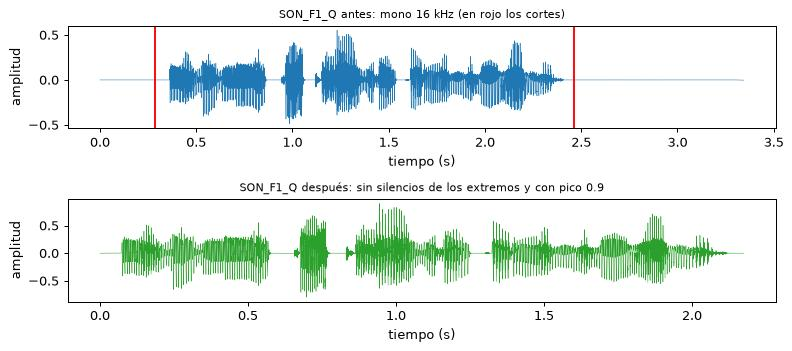

In [31]:
VENTANA, SALTO = 400, 160
UMBRAL_DB, MARGEN = -35, 0.05


def recortar_silencio(y):
    # regla: cuadros de 25 ms cada 10 ms, se busca el primer y el último cuadro con energía RMS mayor que
    # el máximo menos 35 dB, y se deja un margen de 50 ms antes y después. Las pausas internas no se tocan.
    rms = librosa.feature.rms(y=y, frame_length=VENTANA, hop_length=SALTO, center=True)[0]
    db = 20 * np.log10(rms / rms.max() + 1e-12)
    activos = np.nonzero(db > UMBRAL_DB)[0]
    ini = max(0, activos[0] * SALTO - VENTANA // 2 - int(MARGEN * SR))
    fin = min(len(y), activos[-1] * SALTO + VENTANA // 2 + int(MARGEN * SR))
    return ini, fin


def normalizar_pico(y):
    return 0.9 * y / np.abs(y).max()


PROC16, filas = {}, []
for i in ids_son:
    ini, fin = recortar_silencio(MONO16[i])
    PROC16[i] = normalizar_pico(MONO16[i][ini:fin])
    sf.write(PROC / 'sonido' / f'{i}.wav', PROC16[i], SR)
    filas.append({'id': i, 'recorte inicio (s)': round(ini / SR, 3), 'recorte final (s)': round((len(MONO16[i]) - fin) / SR, 3),
                  'duración antes (s)': round(len(MONO16[i]) / SR, 3), 'duración después (s)': round(len(PROC16[i]) / SR, 3)})
recortes = pd.DataFrame(filas)
recortes.to_csv(RES / 'ej7_recortes.csv', index=False)
display(recortes.style.hide(axis='index'))

i = 'SON_F1_Q'
ini, fin = recortar_silencio(MONO16[i])
t = np.arange(len(MONO16[i])) / SR
fig, ax = plt.subplots(2, 1, figsize=(9, 4))
ax[0].plot(t, MONO16[i], lw=0.4); ax[0].axvline(ini / SR, color='r'); ax[0].axvline(fin / SR, color='r')
ax[0].set_title(f'{i} antes: mono 16 kHz (en rojo los cortes)', fontsize=9); ax[0].set_xlabel('tiempo (s)'); ax[0].set_ylabel('amplitud')
ax[1].plot(np.arange(len(PROC16[i])) / SR, PROC16[i], lw=0.4, color='tab:green')
ax[1].set_title(f'{i} después: sin silencios de los extremos y con pico 0.9', fontsize=9); ax[1].set_xlabel('tiempo (s)'); ax[1].set_ylabel('amplitud')
plt.tight_layout(); plt.savefig(RES / 'ej7_onda.png', dpi=120); plt.show()

Regla de recorte: divido la señal en cuadros de 25 ms cada 10 ms, calculo la energía RMS y tomo como voz los cuadros que están a menos de 35 dB del cuadro más fuerte. Corto antes del primero y después del último de esos cuadros, dejando 50 ms de margen. Como solo se cortan los extremos, las pausas internas quedan. Se cortan entre 0.168 y 0.298 s al principio y entre 0.658 y 0.900 s al final, y revisando las ondas el corte cae siempre en silencio, antes y después de la voz (en SON_F1_Q la voz empieza cerca de 0.35 s y el corte está en 0.288 s).

Normalizo la amplitud al pico 0.9. Así una grabación hecha con otra ganancia o más lejos del micrófono no parece distinta. Lo que se pierde es la intensidad absoluta de cada grabación, o sea qué tan fuerte se habló, que para buscar la misma frase no importa.

c) Calcular un espectrograma con ventana Hamming de 400 muestras, salto de 160 y FFT de 512. Relacionar estos parámetros con 25 ms y 10 ms a 16 kHz. Mostrar ejes y unidades. Registrar el centrado y el padding elegidos, no confundir la longitud de FFT con la duración de la ventana.

ventana = 400 / 16000 = 25 ms, salto = 160 / 16000 = 10 ms
FFT de 512: la ventana de 400 muestras se completa con ceros hasta 512, da 257 frecuencias separadas 31.25 Hz
forma del espectrograma (frecuencias, cuadros): (257, 218)


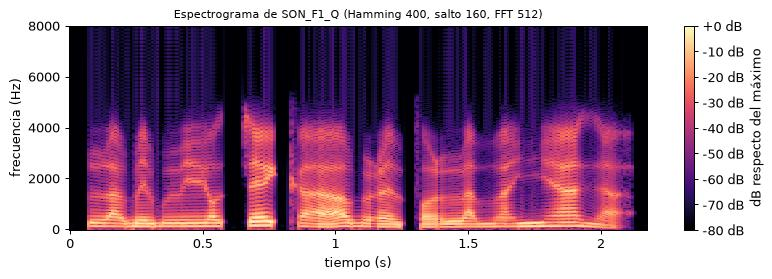

In [32]:
N_FFT = 512
print(f'ventana = {VENTANA} / {SR} = {VENTANA / SR * 1000:.0f} ms, salto = {SALTO} / {SR} = {SALTO / SR * 1000:.0f} ms')
print(f'FFT de {N_FFT}: la ventana de 400 muestras se completa con ceros hasta 512, da {N_FFT // 2 + 1} frecuencias separadas {SR / N_FFT} Hz')
S = librosa.stft(PROC16[i], n_fft=N_FFT, hop_length=SALTO, win_length=VENTANA, window='hamming', center=True, pad_mode='constant')
S_db = librosa.amplitude_to_db(np.abs(S), ref=np.max)
print('forma del espectrograma (frecuencias, cuadros):', S.shape)
fig, ax = plt.subplots(figsize=(9, 3.2))
im = librosa.display.specshow(S_db, sr=SR, hop_length=SALTO, n_fft=N_FFT, win_length=VENTANA, x_axis='time', y_axis='hz', ax=ax)
ax.set_xlabel('tiempo (s)'); ax.set_ylabel('frecuencia (Hz)'); ax.set_title(f'Espectrograma de {i} (Hamming 400, salto 160, FFT 512)', fontsize=9)
fig.colorbar(im, ax=ax, format='%+2.0f dB', label='dB respecto del máximo')
plt.tight_layout(); plt.savefig(RES / 'ej7_espectrograma.png', dpi=120); plt.show()

A 16 kHz, 400 muestras son 400 / 16000 = 0.025 s = 25 ms de ventana, y 160 muestras son 10 ms de salto, o sea un cuadro nuevo cada 10 ms con 15 ms de solape. La FFT de 512 no cambia la duración de la ventana: a las 400 muestras se les agregan 112 ceros y lo que cambia es la cantidad de frecuencias calculadas, 257 bandas separadas 31.25 Hz entre 0 y 8000 Hz. Uso centrado (`center=True`), así que el cuadro t está centrado en la muestra 160 t, con padding de ceros en los bordes (`pad_mode='constant'`). El espectrograma de SON_F1_Q tiene forma 257 x 218, con el tiempo en segundos, la frecuencia en Hz y la intensidad en dB respecto del máximo.

d) Extraer 13 MFCC por cuadro con la misma configuración para todos los audios. Registrar número de bandas Mel y demás parámetros. Mostrar la forma 13 × T y explicar por qué T puede cambiar entre archivos. Construir un vector de 26 valores concatenando media y desvío temporal de cada coeficiente, con desvío poblacional.

In [33]:
P_MFCC = dict(sr=SR, n_mfcc=13, n_fft=N_FFT, hop_length=SALTO, win_length=VENTANA, window='hamming', center=True,
              pad_mode='constant', n_mels=40, fmin=0, fmax=SR / 2, power=2.0, dct_type=2, norm='ortho')
print('parámetros MFCC:', P_MFCC)

MFCC = {i: librosa.feature.mfcc(y=PROC16[i], **P_MFCC) for i in ids_son}
V26 = {i: np.concatenate([m.mean(axis=1), m.std(axis=1, ddof=0)]) for i, m in MFCC.items()}
pd.DataFrame({'id': ids_son, 'forma MFCC': [MFCC[i].shape for i in ids_son], 'muestras': [len(PROC16[i]) for i in ids_son],
              '1 + muestras // 160': [1 + len(PROC16[i]) // SALTO for i in ids_son]}).T

parámetros MFCC: {'sr': 16000, 'n_mfcc': 13, 'n_fft': 512, 'hop_length': 160, 'win_length': 400, 'window': 'hamming', 'center': True, 'pad_mode': 'constant', 'n_mels': 40, 'fmin': 0, 'fmax': 8000.0, 'power': 2.0, 'dct_type': 2, 'norm': 'ortho'}


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
id,SON_F1_B1,SON_F1_B2,SON_F1_B3,SON_F2_B1,SON_F2_B2,SON_F2_B3,SON_F3_B1,SON_F3_B2,SON_F3_B3,SON_F4_B1,SON_F4_B2,SON_F4_B3,SON_F1_Q,SON_F2_Q,SON_F3_Q,SON_F4_Q
forma MFCC,"(13, 188)","(13, 181)","(13, 169)","(13, 200)","(13, 192)","(13, 179)","(13, 177)","(13, 170)","(13, 160)","(13, 190)","(13, 183)","(13, 171)","(13, 218)","(13, 232)","(13, 206)","(13, 220)"
muestras,30000,28880,26960,31920,30640,28560,28240,27120,25520,30320,29200,27280,34800,37040,32880,35120
1 + muestras // 160,188,181,169,200,192,179,177,170,160,190,183,171,218,232,206,220


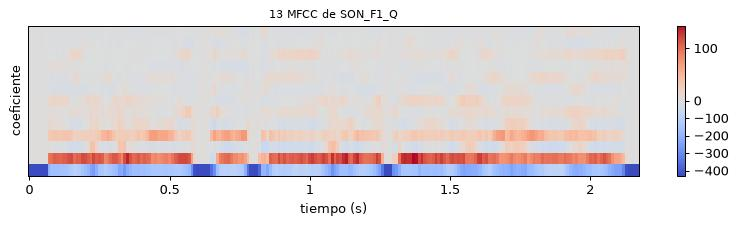

vector resumido: (26,)


In [34]:
fig, ax = plt.subplots(figsize=(9, 2.6))
im = librosa.display.specshow(MFCC['SON_F1_Q'], sr=SR, hop_length=SALTO, x_axis='time', ax=ax)
ax.set_ylabel('coeficiente'); ax.set_xlabel('tiempo (s)'); ax.set_title('13 MFCC de SON_F1_Q', fontsize=9)
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig(RES / 'ej7_mfcc.png', dpi=120); plt.show()
print('vector resumido:', V26['SON_F1_Q'].shape)

Parámetros: 13 coeficientes, 40 bandas Mel entre 0 y 8000 Hz, espectro de potencia (power = 2), DCT tipo 2 ortonormal y la misma ventana Hamming de 400, salto de 160, FFT de 512 y centrado del espectrograma. Son iguales para los 16 audios. Cada audio da una matriz 13 x T con T = 1 + muestras // 160 por el centrado. T cambia porque cada grabación dura distinto: va de 160 cuadros en SON_F3_B3 (1.595 s) a 232 en SON_F2_Q (2.315 s), y las consultas, que se dijeron más lento, tienen más cuadros. El vector de 26 junta la media y el desvío poblacional (ddof = 0) de cada coeficiente a lo largo del tiempo.

e) Construir también la secuencia de 39 características por cuadro: 13 MFCC, 13 deltas y 13 deltas de segundo orden. Registrar la ventana usada para deltas y comprobar que hay suficientes cuadros.

In [35]:
ANCHO_DELTA = 9  # 4 cuadros a cada lado, 90 ms
SEQ39 = {}
for i, m in MFCC.items():
    assert m.shape[1] >= ANCHO_DELTA, i
    SEQ39[i] = np.vstack([m, librosa.feature.delta(m, width=ANCHO_DELTA, order=1),
                          librosa.feature.delta(m, width=ANCHO_DELTA, order=2)])
print('ventana de deltas:', ANCHO_DELTA, 'cuadros. Menor cantidad de cuadros:', min(s.shape[1] for s in SEQ39.values()))
print('forma de la secuencia de SON_F1_Q:', SEQ39['SON_F1_Q'].shape)
np.savez_compressed(CARAC / 'sonido_mfcc26.npz', ids=np.array(ids_son), X=np.array([V26[i] for i in ids_son], dtype=np.float32))
np.savez_compressed(CARAC / 'sonido_mfcc39_secuencias.npz', **{i: SEQ39[i].astype(np.float32) for i in ids_son})

ventana de deltas: 9 cuadros. Menor cantidad de cuadros: 160
forma de la secuencia de SON_F1_Q: (39, 218)


Las deltas de primer y segundo orden usan una ventana de 9 cuadros (4 a cada lado, 90 ms). El audio más corto tiene 160 cuadros, mucho más que 9, así que alcanza en todos. La secuencia de SON_F1_Q queda de 39 x 218.

Dos buscadores sobre los mismos audios

Buscador A: estandarizar las 26 coordenadas usando media y desvío calculados sobre los 12 vectores de la base, reutilizar esas estadísticas en consultas. Para coordenadas con desvío cero, usar divisor 1. Recuperar por distancia euclidiana.

Buscador B: usar las secuencias de 39 características con DTW y costo local euclidiano. Estandarizar cada característica con estadísticas de todos los cuadros válidos de la base. Usar costo acumulado sin dividir por la longitud del camino, pasos horizontal/vertical/diagonal y extremos obligatorios. Informar el efecto posible de las duraciones diferentes.

Obtener top 3 para cada consulta en ambos buscadores. Graficar un camino DTW entre una consulta y una grabación relevante. Explicar qué información pierde el resumen de 26 valores y qué gana, en costo, frente a conservar una secuencia.

In [36]:
B26 = np.array([V26[b] for b in base_son])
MU26, SD26 = B26.mean(axis=0), B26.std(axis=0)
print('coordenadas con desvío cero en la base:', int((SD26 == 0).sum()))
SD26[SD26 == 0] = 1  # divisor 1 para desvío cero


def estandarizar26(v):
    return (v - MU26) / SD26


TABLAS_SON = {}
D_A = dist_euclidiana([estandarizar26(V26[q]) for q in cons_son], [estandarizar26(V26[b]) for b in base_son])
TABLAS_SON['MFCC 26 + euclidiana'] = evaluar('sonido', 'MFCC 26 + euclidiana', cons_son, base_son, D_A, RELEVANTES, explicar_son)
display(mostrar(TABLAS_SON['MFCC 26 + euclidiana']))

coordenadas con desvío cero en la base: 0


consulta,top3,distancias,relevantes,P@3,R@3
SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F1_B3","2.4324, 4.3204, 5.5605",3,1.0000,1.0000
SON_F2_Q,"SON_F2_B2, SON_F2_B1, SON_F2_B3","2.4336, 2.7261, 3.3833",3,1.0000,1.0000
SON_F3_Q,"SON_F3_B3, SON_F3_B2, SON_F3_B1","2.4876, 2.8450, 3.1774",3,1.0000,1.0000
SON_F4_Q,"SON_F4_B2, SON_F4_B3, SON_F4_B1","1.8130, 2.8594, 3.2507",3,1.0000,1.0000


In [37]:
cuadros_base = np.hstack([SEQ39[b] for b in base_son])  # todos los cuadros de la base
MU39, SD39 = cuadros_base.mean(axis=1, keepdims=True), cuadros_base.std(axis=1, keepdims=True)
SD39[SD39 == 0] = 1


def estandarizar39(s):
    return ((s - MU39) / SD39).T  # T x 39


def dtw(A, B):
    # costo local euclidiano, pasos horizontal, vertical y diagonal, extremos obligatorios, sin dividir por el largo
    C = np.sqrt(np.maximum((A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T, 0))
    n, m = C.shape
    D = [[float('inf')] * (m + 1) for _ in range(n + 1)]
    D[0][0] = 0.0
    Cl = C.tolist()
    for i in range(1, n + 1):
        Di, Dp, Ci = D[i], D[i - 1], Cl[i - 1]
        for j in range(1, m + 1):
            Di[j] = Ci[j - 1] + min(Dp[j], Di[j - 1], Dp[j - 1])
    camino, i, j = [(n - 1, m - 1)], n, m
    while (i, j) != (1, 1):
        i, j = min([(i - 1, j - 1), (i - 1, j), (i, j - 1)], key=lambda p: D[p[0]][p[1]])
        camino.append((i - 1, j - 1))
    return D[n][m], camino[::-1], C


Z39 = {i: estandarizar39(SEQ39[i]) for i in ids_son}
D_B = np.array([[dtw(Z39[q], Z39[b])[0] for b in base_son] for q in cons_son])
TABLAS_SON['MFCC 39 + DTW'] = evaluar('sonido', 'MFCC 39 + DTW', cons_son, base_son, D_B, RELEVANTES, explicar_son)
display(mostrar(TABLAS_SON['MFCC 39 + DTW']))
pd.DataFrame(D_B, index=cons_son, columns=base_son).rename_axis('consulta').to_csv(RES / 'ej7_costos_dtw.csv')
pd.DataFrame(D_B, index=cons_son, columns=base_son).round(1)

consulta,top3,distancias,relevantes,P@3,R@3
SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F1_B3","424.2882, 482.8105, 538.1541",3,1.0000,1.0000
SON_F2_Q,"SON_F2_B1, SON_F2_B2, SON_F2_B3","480.2789, 508.6463, 576.0188",3,1.0000,1.0000
SON_F3_Q,"SON_F3_B1, SON_F3_B2, SON_F3_B3","436.5398, 446.7869, 490.3972",3,1.0000,1.0000
SON_F4_Q,"SON_F4_B1, SON_F4_B2, SON_F4_B3","470.4769, 477.5568, 558.7093",3,1.0000,1.0000


,SON_F1_B1,SON_F1_B2,SON_F1_B3,SON_F2_B1,SON_F2_B2,SON_F2_B3,SON_F3_B1,SON_F3_B2,SON_F3_B3,SON_F4_B1,SON_F4_B2,SON_F4_B3
SON_F1_Q,424.3000,482.8000,538.2000,700.2000,694.8000,756.6000,1199.0000,1202.6000,1207.5000,1432.9000,1403.9000,1412.5000
SON_F2_Q,720.8000,761.4000,814.9000,480.3000,508.6000,576.0000,1437.2000,1447.8000,1452.1000,1257.7000,1227.3000,1243.2000
SON_F3_Q,1187.9000,1199.9000,1174.1000,1381.0000,1367.1000,1327.4000,436.5000,446.8000,490.4000,680.8000,696.0000,725.0000
SON_F4_Q,1422.1000,1428.5000,1395.2000,1210.7000,1218.6000,1210.5000,746.6000,722.8000,793.1000,470.5000,477.6000,558.7000


costo DTW SON_F1_Q - SON_F1_B3: 538.15, largo del camino: 218 pasos, cuadros: 218 x 169


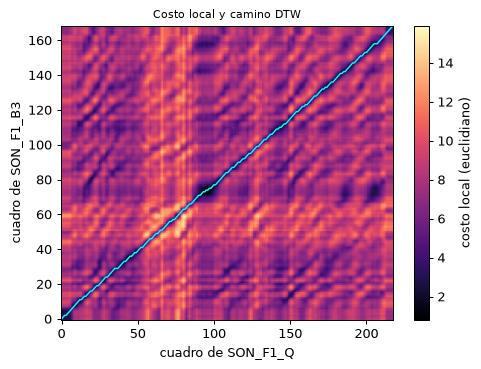

In [38]:
q, b = 'SON_F1_Q', 'SON_F1_B3'
costo, camino, C = dtw(Z39[q], Z39[b])
print(f'costo DTW {q} - {b}: {costo:.2f}, largo del camino: {len(camino)} pasos, cuadros: {Z39[q].shape[0]} x {Z39[b].shape[0]}')
fig, ax = plt.subplots(figsize=(5.5, 4.2))
im = ax.imshow(C.T, origin='lower', aspect='auto', cmap='magma')
ax.plot([p[0] for p in camino], [p[1] for p in camino], color='cyan', lw=1.2)
ax.set_xlabel(f'cuadro de {q}'); ax.set_ylabel(f'cuadro de {b}'); ax.set_title('Costo local y camino DTW', fontsize=9)
fig.colorbar(im, ax=ax, label='costo local (euclidiano)')
plt.tight_layout(); plt.savefig(RES / 'ej7_dtw.png', dpi=120); plt.show()

Buscador A: la media y el desvío de las 26 coordenadas salen de los 12 vectores de base y se reutilizan para las consultas. Ninguna coordenada tuvo desvío cero, igual el código usa divisor 1 en ese caso. Buscador B: cada una de las 39 características se estandariza con la media y el desvío de los 2160 cuadros de la base, y DTW usa costo local euclidiano, pasos horizontal, vertical y diagonal, extremos obligatorios y costo acumulado sin dividir por el largo del camino.

Los dos buscadores recuperan las tres grabaciones de la misma frase en las cuatro consultas (P@3 = R@3 = 1). En DTW se ve el efecto de las duraciones: como el costo se suma paso a paso y no se divide por el largo, para las cuatro consultas la grabación de base más cercana es B1 (la más lenta, 175 palabras por minuto) y la más lejana es B3 (la más rápida, 205), por ejemplo 424.29 contra 538.15 para SON_F1_Q. Cuanto más distinta la duración, más pasos horizontales o verticales necesita el camino y más costo junta, aunque sea la misma frase. Con estas grabaciones igual alcanza, porque la frase equivocada más cercana queda mucho más lejos (de SON_F1_Q a F2 hay entre 694.8 y 756.6).

El gráfico muestra el camino entre SON_F1_Q (218 cuadros) y SON_F1_B3 (169 cuadros). Sigue la zona de costo bajo en una diagonal con pendiente menor que 1: como la consulta tiene más cuadros, cada tanto el camino da un paso horizontal y dos cuadros de la consulta se alinean con el mismo cuadro de la base. Esos pasos están repartidos en toda la frase porque la consulta es más lenta de manera pareja.

El resumen de 26 valores pierde el orden temporal y la duración de cada parte: la media y el desvío serían iguales si los cuadros se dijeran en otro orden. A cambio, cada audio es un vector fijo de 26 números (1248 bytes toda la base contra 336960 de las secuencias) y comparar dos audios son 26 restas. Con DTW cada par necesita llenar una matriz de T1 x T2 celdas (218 x 169 = 36842 en el ejemplo), cada una con una distancia de 39 dimensiones.

## Ejercicio 8. Sonido con un encoder preentrenado

Se incorpora un extractor aprendido para comparar su representación con MFCC, sin entrenar un reconocedor de frases. Usar wav2vec 2.0 con el checkpoint facebook/wav2vec2-base indicado en la presentación. Su utilidad para estas frases en español debe evaluarse, no se presupone que el espacio codifique perfectamente su significado.

a) Utilizar los audios mono a 16 kHz del ejercicio anterior y el procesador asociado al checkpoint. Ejecutar el modelo en modo evaluación e inferencia. No convertir la matriz de MFCC en entrada de este modelo, que recibe la onda.

In [39]:
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model

proc_w2v = Wav2Vec2FeatureExtractor.from_pretrained('facebook/wav2vec2-base')
w2v = Wav2Vec2Model.from_pretrained('facebook/wav2vec2-base', use_safetensors=False).eval()
print(proc_w2v)

Wav2Vec2FeatureExtractor {
  "do_normalize": true,
  "feature_extractor_type": "Wav2Vec2FeatureExtractor",
  "feature_size": 1,
  "padding_side": "right",
  "padding_value": 0.0,
  "return_attention_mask": false,
  "sampling_rate": 16000
}



Uso el procesador (`Wav2Vec2FeatureExtractor`) y el modelo (`Wav2Vec2Model`) del checkpoint facebook/wav2vec2-base. Entran las ondas mono de 16 kHz ya recortadas y normalizadas del ejercicio 7, y el procesador las lleva a media 0 y desvío 1 (`do_normalize`). El modelo está en `eval()` y la extracción corre dentro de `torch.inference_mode()`. Al modelo le paso la onda, no los MFCC.

b) Procesar un archivo por vez, sin padding de lote. Extraer hidden_states[6], como en el ejemplo de clase, y registrar la forma T′ × D obtenida. Explicar por qué T′ no coincide con el número de muestras de la onda ni necesariamente con los cuadros MFCC.

In [40]:
@torch.inference_mode()
def estados_w2v(y):
    ent = proc_w2v(y, sampling_rate=SR, return_tensors='pt')  # un archivo, sin padding
    out = w2v(ent.input_values, output_hidden_states=True)
    return out.hidden_states[6][0].numpy()  # T' x D


H6 = {i: estados_w2v(PROC16[i]) for i in ids_son}
pd.DataFrame({'id': ids_son, 'muestras': [len(PROC16[i]) for i in ids_son], 'cuadros MFCC (T)': [MFCC[i].shape[1] for i in ids_son],
              "forma hidden_states[6] (T' x D)": [H6[i].shape for i in ids_son],
              'muestras / 320': [round(len(PROC16[i]) / 320, 1) for i in ids_son]}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
id,SON_F1_B1,SON_F1_B2,SON_F1_B3,SON_F2_B1,SON_F2_B2,SON_F2_B3,SON_F3_B1,SON_F3_B2,SON_F3_B3,SON_F4_B1,SON_F4_B2,SON_F4_B3,SON_F1_Q,SON_F2_Q,SON_F3_Q,SON_F4_Q
muestras,30000,28880,26960,31920,30640,28560,28240,27120,25520,30320,29200,27280,34800,37040,32880,35120
cuadros MFCC (T),188,181,169,200,192,179,177,170,160,190,183,171,218,232,206,220
forma hidden_states[6] (T' x D),"(93, 768)","(90, 768)","(84, 768)","(99, 768)","(95, 768)","(89, 768)","(88, 768)","(84, 768)","(79, 768)","(94, 768)","(91, 768)","(85, 768)","(108, 768)","(115, 768)","(102, 768)","(109, 768)"
muestras / 320,93.8000,90.2000,84.2000,99.8000,95.8000,89.2000,88.2000,84.8000,79.8000,94.8000,91.2000,85.2000,108.8000,115.8000,102.8000,109.8000


Cada archivo entra solo, sin padding. hidden_states[6] es la salida de la sexta capa del transformer (el índice 0 es la entrada al transformer) y da T' x 768, por ejemplo 108 x 768 para SON_F1_Q. T' es mucho menor que la cantidad de muestras porque el codificador convolucional de wav2vec 2.0 resume la onda con un paso total de 320 muestras (20 ms a 16 kHz) y una ventana de unas 400 (25 ms), así que T' es aproximadamente muestras / 320. Los MFCC usan un salto de 160 muestras (10 ms) y centrado, así que tienen casi el doble de cuadros: 218 contra 108 en SON_F1_Q.

c) Aplicar promedio sobre el eje temporal para obtener D componentes y normalizar a norma L2. Registrar D observado. Construir un segundo descriptor concatenando media y desvío temporal, de dimensión 2D, y normalizarlo. Mantener separados ambos espacios de representación.

In [41]:
W_MEDIA = {i: normalizar_l2(h.mean(axis=0)) for i, h in H6.items()}
W_MEDIA_DESVIO = {i: normalizar_l2(np.concatenate([h.mean(axis=0), h.std(axis=0)])) for i, h in H6.items()}
print('D observado:', W_MEDIA[ids_son[0]].shape[0], ' descriptor media y desvío:', W_MEDIA_DESVIO[ids_son[0]].shape[0])
print('normas:', round(min(np.linalg.norm(v) for v in W_MEDIA.values()), 6), round(max(np.linalg.norm(v) for v in W_MEDIA_DESVIO.values()), 6))
np.savez_compressed(CARAC / 'sonido_w2v_media.npz', ids=np.array(ids_son), X=np.array([W_MEDIA[i] for i in ids_son], dtype=np.float32))
np.savez_compressed(CARAC / 'sonido_w2v_media_desvio.npz', ids=np.array(ids_son), X=np.array([W_MEDIA_DESVIO[i] for i in ids_son], dtype=np.float32))

D observado: 768  descriptor media y desvío: 1536
normas: 1.0 1.0


D observado = 768. El promedio en el tiempo da un vector de 768 y la concatenación de media y desvío uno de 1536, los dos normalizados a norma 1. Son dos buscadores separados, nunca se compara un vector de un espacio con uno del otro.

d) Recuperar top 3 por distancia coseno para las cuatro consultas con los dos descriptores. Comparar con MFCC resumidos y MFCC con DTW. Analizar especialmente F1 frente a F2 y F3 frente a F4: comparten muchas palabras, pero una diferencia cambia el contenido.

In [42]:
for nombre, desc in [('wav2vec2 media + coseno', W_MEDIA), ('wav2vec2 media y desvío + coseno', W_MEDIA_DESVIO)]:
    D = dist_coseno([desc[q] for q in cons_son], [desc[b] for b in base_son])
    TABLAS_SON[nombre] = evaluar('sonido', nombre, cons_son, base_son, D, RELEVANTES, explicar_son)
pd.concat(TABLAS_SON.values())[['representacion', 'consulta', 'top3', 'distancias', 'relevantes', 'P@3']].style.format({'P@3': '{:.4f}'}).hide(axis='index')

representacion,consulta,top3,distancias,relevantes,P@3
MFCC 26 + euclidiana,SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F1_B3","2.4324, 4.3204, 5.5605",3,1.0000
MFCC 26 + euclidiana,SON_F2_Q,"SON_F2_B2, SON_F2_B1, SON_F2_B3","2.4336, 2.7261, 3.3833",3,1.0000
MFCC 26 + euclidiana,SON_F3_Q,"SON_F3_B3, SON_F3_B2, SON_F3_B1","2.4876, 2.8450, 3.1774",3,1.0000
MFCC 26 + euclidiana,SON_F4_Q,"SON_F4_B2, SON_F4_B3, SON_F4_B1","1.8130, 2.8594, 3.2507",3,1.0000
MFCC 39 + DTW,SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F1_B3","424.2882, 482.8105, 538.1541",3,1.0000
MFCC 39 + DTW,SON_F2_Q,"SON_F2_B1, SON_F2_B2, SON_F2_B3","480.2789, 508.6463, 576.0188",3,1.0000
MFCC 39 + DTW,SON_F3_Q,"SON_F3_B1, SON_F3_B2, SON_F3_B3","436.5398, 446.7869, 490.3972",3,1.0000
MFCC 39 + DTW,SON_F4_Q,"SON_F4_B1, SON_F4_B2, SON_F4_B3","470.4769, 477.5568, 558.7093",3,1.0000
wav2vec2 media + coseno,SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F2_B2","0.0302, 0.0430, 0.0519",2,0.6667
wav2vec2 media + coseno,SON_F2_Q,"SON_F2_B1, SON_F2_B2, SON_F2_B3","0.0366, 0.0381, 0.0831",3,1.0000


In [43]:
# distancia media de cada consulta a las grabaciones de cada frase
filas = []
for rep, D in [('MFCC 26 + euclidiana', D_A), ('MFCC 39 + DTW', D_B),
               ('wav2vec2 media + coseno', dist_coseno([W_MEDIA[q] for q in cons_son], [W_MEDIA[b] for b in base_son])),
               ('wav2vec2 media y desvío + coseno', dist_coseno([W_MEDIA_DESVIO[q] for q in cons_son], [W_MEDIA_DESVIO[b] for b in base_son]))]:
    for k, q in enumerate(cons_son):
        fila = {'representación': rep, 'consulta': q}
        for f in FRASES:
            fila[f] = D[k, [j for j, b in enumerate(base_son) if b.split('_')[1] == f]].mean()
        filas.append(fila)
pd.DataFrame(filas).to_csv(RES / 'ej8_distancia_media_por_frase.csv', index=False)
pd.DataFrame(filas).style.format({f: '{:.4f}' for f in FRASES}).hide(axis='index')

representación,consulta,F1,F2,F3,F4
MFCC 26 + euclidiana,SON_F1_Q,4.1044,7.8680,6.8599,9.9617
MFCC 26 + euclidiana,SON_F2_Q,7.8778,2.8477,7.7977,5.7052
MFCC 26 + euclidiana,SON_F3_Q,7.5045,8.6234,2.8367,6.8634
MFCC 26 + euclidiana,SON_F4_Q,10.7946,7.2227,7.2128,2.6410
MFCC 39 + DTW,SON_F1_Q,481.7509,717.2096,1203.0197,1416.4398
MFCC 39 + DTW,SON_F2_Q,765.7168,521.6480,1445.6868,1242.7204
MFCC 39 + DTW,SON_F3_Q,1187.2866,1358.5081,457.9080,700.5882
MFCC 39 + DTW,SON_F4_Q,1415.2798,1213.2621,754.1392,502.2477
wav2vec2 media + coseno,SON_F1_Q,0.0588,0.0626,0.1074,0.1222
wav2vec2 media + coseno,SON_F2_Q,0.1272,0.0526,0.1439,0.1026


Los dos descriptores de wav2vec aciertan 11 de 12 (P@3 media 0.9167), contra 12 de 12 de los dos buscadores MFCC. El error es el mismo en los dos: para SON_F1_Q el tercer resultado es SON_F2_B2, la frase que solo cambia abre por cierra, y SON_F1_B3 queda fuera del top 3.

F1 frente a F2: en la tabla de distancias medias, SON_F1_Q queda casi igual de cerca de F1 que de F2 con wav2vec (0.0588 contra 0.0626 con la media), mientras que con MFCC la diferencia es clara (4.1044 contra 7.8680 con el resumen y 481.75 contra 717.21 con DTW). F3 frente a F4 se separa mejor en todas (SON_F3_Q: 0.0450 contra 0.0654 con wav2vec). Al promediar en el tiempo, abre o cierra es una palabra de seis y cambia poco el promedio. Además wav2vec2-base se preentrenó con audio en inglés y sin etiquetas, así que no hay garantía de que su espacio separe bien palabras en español. DTW, en cambio, compara cuadro a cuadro y la palabra distinta suma costo en su tramo.

## Interpretación de las representaciones acústicas

Responder a partir de las observaciones de los ejercicios 7 y 8:

a) ¿Qué representación conserva el orden temporal y cuáles lo descartan al resumir? ¿Qué consecuencias tiene esa diferencia cuando solo cambia la velocidad de pronunciación?

b) ¿Los vecinos recuperados parecen compartir frase, timbre, duración o energía? Ilustrar la respuesta con dos pares concretos. Un buen resultado con un único hablante no demuestra que el buscador sea independiente de la voz.

c) Si se quisiera recuperar al mismo hablante diciendo frases diferentes, ¿seguiría siendo válida la relevancia definida en el ejercicio 1? Proponer una colección y una representación apropiadas.

d) Si se quisiera reconocer la misma grabación con ruido o compresión, ¿qué enfoque de la presentación sería más específico?

In [44]:
# duración y energía de cada grabación procesada, para ver qué comparten los vecinos
pd.DataFrame({'id': ids_son, 'duración (s)': [round(len(PROC16[i]) / SR, 3) for i in ids_son],
              'energía RMS': [round(float(np.sqrt((PROC16[i] ** 2).mean())), 4) for i in ids_son]}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
id,SON_F1_B1,SON_F1_B2,SON_F1_B3,SON_F2_B1,SON_F2_B2,SON_F2_B3,SON_F3_B1,SON_F3_B2,SON_F3_B3,SON_F4_B1,SON_F4_B2,SON_F4_B3,SON_F1_Q,SON_F2_Q,SON_F3_Q,SON_F4_Q
duración (s),1.8750,1.8050,1.6850,1.9950,1.9150,1.7850,1.7650,1.6950,1.5950,1.8950,1.8250,1.7050,2.1750,2.3150,2.0550,2.1950
energía RMS,0.1717,0.1738,0.1681,0.1827,0.1804,0.1791,0.1654,0.1551,0.1609,0.1712,0.1801,0.1775,0.1585,0.1762,0.1629,0.1708


a) Solo MFCC 39 con DTW conserva el orden temporal, porque compara las secuencias cuadro a cuadro y el alineamiento puede estirar o comprimir partes. MFCC 26 y los dos descriptores de wav2vec resumen con media (y desvío) y descartan el orden. Cuando solo cambia la velocidad, el resumen casi no cambia, porque los mismos sonidos duran más pero sus promedios se parecen. DTW absorbe el cambio con pasos horizontales o verticales, pero como el costo no se divide por el largo, la consulta lenta suma más costo con las grabaciones más rápidas: para SON_F1_Q el costo con B1 (175 palabras por minuto) es 424.29 y con B3 (205) es 538.15.

b) Los vecinos comparten sobre todo la frase. Dentro de la misma frase, en DTW los ordena la duración: SON_F1_Q (2.175 s) tiene más cerca a SON_F1_B1 (1.875 s, la base más larga) que a SON_F1_B3 (1.685 s), y lo mismo pasa en las otras tres consultas. Con wav2vec, el par SON_F1_Q y SON_F2_B2 (0.0519) muestra que el vecino puede compartir casi todo el sonido y no la frase, porque solo cambia una palabra. La energía no explica los vecinos porque está normalizada al pico y las energías RMS quedan todas entre 0.1551 y 0.1827. El timbre no se puede evaluar porque todas las grabaciones tienen la misma voz, y encima es una voz sintetizada que dice cada sonido casi igual. Por eso que funcione acá no demuestra que el buscador sea independiente de la voz: con otra persona cambian el timbre, la altura y la forma de pronunciar, y un buscador acústico podría acercar grabaciones de la misma voz antes que de la misma frase.

c) No. La relevancia del ejercicio 1 es "otra grabación de la misma frase", y para buscar al mismo hablante lo relevante sería cualquier grabación de esa persona, diga lo que diga. Habría que armar una colección con varios hablantes (por ejemplo 10), cada uno diciendo frases distintas en sesiones distintas, con consultas que sean frases que ese hablante no tenga en la base, y definir como relevantes las grabaciones del mismo hablante. Como representación usaría un embedding de hablante (tipo x-vector o ECAPA) promediado en el tiempo, que está entrenado para capturar la voz e ignorar el contenido. Sin ese modelo, MFCC resumidos con media y desvío también sirven como base, porque guardan el timbre y descartan el orden de las palabras.

d) Para reconocer la misma grabación con ruido o compresión lo más específico es una huella acústica (audio fingerprinting, como Shazam): se buscan los picos del espectrograma y se arman hashes con pares de picos y su diferencia de tiempo. Resiste ruido y compresión porque los picos fuertes sobreviven, y no busca otras pronunciaciones, solo la misma grabación.

## Ejercicio 9. Evaluar y justificar las representaciones

La calidad se evalúa con las consultas principales y los conjuntos relevantes definidos antes de ejecutar las búsquedas. Presentar resultados por modalidad, los puntajes de distintos espacios no son directamente comparables.

$$Precisión@3 = \frac{\text{relevantes entre los 3 recuperados}}{3} \qquad Recall@3 = \frac{\text{relevantes entre los 3 recuperados}}{\text{total de relevantes en la base}}$$

En texto hay 2 relevantes por consulta: una recuperación perfecta obtiene Recall@3 = 1 y Precisión@3 = 2/3. En imágenes y sonido hay 3 relevantes: ambas métricas pueden llegar a 1. Si una consulta produce un vector nulo y no se devuelven resultados, registrar el caso y puntuar ambas métricas con 0 en el promedio principal.

a) Para cada consulta y representación, registrar los 3 primeros IDs, su distancia, cuántos son relevantes, precisión en 3 y recall en 3. Mostrar también la respuesta humana a por qué cada resultado es o no útil.

In [45]:
EVAL = pd.DataFrame(EVALUACION)
EVAL.to_csv(RES / 'ej9_resultados_por_consulta.csv', index=False)
for m in ['imagen', 'texto', 'sonido']:
    print(m.upper())
    display(EVAL[EVAL.modalidad == m].drop(columns='modalidad').style.format({'P@3': '{:.4f}', 'R@3': '{:.4f}'}).hide(axis='index'))

IMAGEN


representacion,consulta,top3,distancias,relevantes,P@3,R@3,por qué
píxeles + coseno,IMG_O1_Q,"IMG_O1_B1, IMG_O1_B3, IMG_O1_B2","0.0689, 0.0746, 0.0811",3,1.0000,1.0000,"IMG_O1_B1: sí, otra foto del mismo objeto / IMG_O1_B3: sí, otra foto del mismo objeto / IMG_O1_B2: sí, otra foto del mismo objeto"
píxeles + coseno,IMG_O2_Q,"IMG_O2_B2, IMG_O5_B3, IMG_O6_B2","0.0332, 0.0341, 0.0359",1,0.3333,0.3333,"IMG_O2_B2: sí, otra foto del mismo objeto / IMG_O5_B3: no, es el barco azul, comparte el color y el fondo (pared) / IMG_O6_B2: no, es el barco verde, comparte el fondo (pared)"
píxeles + coseno,IMG_O3_Q,"IMG_O3_B1, IMG_O4_B3, IMG_O1_B2","0.0735, 0.0755, 0.0814",1,0.3333,0.3333,"IMG_O3_B1: sí, otra foto del mismo objeto / IMG_O4_B3: no, es el morrón verde, comparte la forma y el fondo (mantel) / IMG_O1_B2: no, es el aro rojo, comparte el color y el fondo (mantel)"
píxeles + coseno,IMG_O4_Q,"IMG_O4_B2, IMG_O3_B3, IMG_O6_B2","0.0725, 0.0911, 0.1080",1,0.3333,0.3333,"IMG_O4_B2: sí, otra foto del mismo objeto / IMG_O3_B3: no, es el morrón rojo, comparte la forma y el fondo (madera) / IMG_O6_B2: no, es el barco verde, comparte el color"
píxeles + coseno,IMG_O5_Q,"IMG_O5_B3, IMG_O2_B3, IMG_O2_B2","0.0378, 0.0475, 0.0559",1,0.3333,0.3333,"IMG_O5_B3: sí, otra foto del mismo objeto / IMG_O2_B3: no, es el aro azul, comparte el color y el fondo (escritorio) / IMG_O2_B2: no, es el aro azul, comparte el color"
píxeles + coseno,IMG_O6_Q,"IMG_O6_B2, IMG_O2_B2, IMG_O5_B3","0.0248, 0.0381, 0.0441",1,0.3333,0.3333,"IMG_O6_B2: sí, otra foto del mismo objeto / IMG_O2_B2: no, es el aro azul, comparte el fondo (pared) / IMG_O5_B3: no, es el barco azul, comparte la forma y el fondo (pared)"
píxeles + euclidiana,IMG_O1_Q,"IMG_O1_B1, IMG_O1_B3, IMG_O1_B2","0.3712, 0.3863, 0.4028",3,1.0000,1.0000,"IMG_O1_B1: sí, otra foto del mismo objeto / IMG_O1_B3: sí, otra foto del mismo objeto / IMG_O1_B2: sí, otra foto del mismo objeto"
píxeles + euclidiana,IMG_O2_Q,"IMG_O2_B2, IMG_O5_B3, IMG_O6_B2","0.2575, 0.2612, 0.2678",1,0.3333,0.3333,"IMG_O2_B2: sí, otra foto del mismo objeto / IMG_O5_B3: no, es el barco azul, comparte el color y el fondo (pared) / IMG_O6_B2: no, es el barco verde, comparte el fondo (pared)"
píxeles + euclidiana,IMG_O3_Q,"IMG_O3_B1, IMG_O4_B3, IMG_O1_B2","0.3833, 0.3887, 0.4035",1,0.3333,0.3333,"IMG_O3_B1: sí, otra foto del mismo objeto / IMG_O4_B3: no, es el morrón verde, comparte la forma y el fondo (mantel) / IMG_O1_B2: no, es el aro rojo, comparte el color y el fondo (mantel)"
píxeles + euclidiana,IMG_O4_Q,"IMG_O4_B2, IMG_O3_B3, IMG_O6_B2","0.3809, 0.4269, 0.4648",1,0.3333,0.3333,"IMG_O4_B2: sí, otra foto del mismo objeto / IMG_O3_B3: no, es el morrón rojo, comparte la forma y el fondo (madera) / IMG_O6_B2: no, es el barco verde, comparte el color"


TEXTO


representacion,consulta,top3,distancias,relevantes,P@3,R@3,por qué
bolsa de palabras + coseno,Q1,"D01, D03, D02","0.2929, 0.8110, 0.8333",2,0.6667,1.0000,"D01: sí, habla de recuperar una contraseña olvidada / D03: no, habla de cambiar una contraseña que se conoce / D02: sí, habla de pedir un enlace para recuperar la clave"
bolsa de palabras + coseno,Q2,"D02, D05, D09","0.5000, 0.8110, 0.8232",1,0.3333,0.5000,"D02: sí, habla de pedir un enlace para recuperar la clave / D05: no, habla de la duración del préstamo de libros / D09: no, habla de el curso de Python sin requisitos"
bolsa de palabras + coseno,Q3,"D04, D05, D01","0.5286, 0.5636, 1.0000",2,0.6667,1.0000,"D04: sí, habla de el préstamo de libros a domicilio por siete días / D05: sí, habla de la duración del préstamo de libros / D01: no, habla de recuperar una contraseña olvidada"
bolsa de palabras + coseno,Q4,"D08, D07, D09","0.4000, 0.4523, 0.6838",2,0.6667,1.0000,"D08: sí, habla de los requisitos para inscribirse en C++ / D07: sí, habla de los requisitos del curso de C++ / D09: no, habla de el curso de Python sin requisitos"
bolsa de palabras + coseno,Q5,"D10, D09, D07","0.3876, 0.4697, 0.5918",2,0.6667,1.0000,"D10: sí, habla de el curso de Python para quien nunca programó / D09: sí, habla de el curso de Python sin requisitos / D07: no, habla de los requisitos del curso de C++"
bolsa de palabras + coseno,Q6,"D11, D12, D01","0.7327, 0.7327, 1.0000",2,0.6667,1.0000,"D11: sí, habla de la beca de transporte / D12: sí, habla de cómo pedir la ayuda para el transporte / D01: no, habla de recuperar una contraseña olvidada"
TF-IDF + coseno,Q1,"D01, D03, D02","0.2929, 0.8392, 0.8619",2,0.6667,1.0000,"D01: sí, habla de recuperar una contraseña olvidada / D03: no, habla de cambiar una contraseña que se conoce / D02: sí, habla de pedir un enlace para recuperar la clave"
TF-IDF + coseno,Q2,"D02, D05, D09","0.5059, 0.7941, 0.8406",1,0.3333,0.5000,"D02: sí, habla de pedir un enlace para recuperar la clave / D05: no, habla de la duración del préstamo de libros / D09: no, habla de el curso de Python sin requisitos"
TF-IDF + coseno,Q3,"D04, D05, D01","0.5444, 0.5820, 1.0000",2,0.6667,1.0000,"D04: sí, habla de el préstamo de libros a domicilio por siete días / D05: sí, habla de la duración del préstamo de libros / D01: no, habla de recuperar una contraseña olvidada"
TF-IDF + coseno,Q4,"D08, D07, D09","0.4589, 0.5109, 0.7471",2,0.6667,1.0000,"D08: sí, habla de los requisitos para inscribirse en C++ / D07: sí, habla de los requisitos del curso de C++ / D09: no, habla de el curso de Python sin requisitos"


SONIDO


representacion,consulta,top3,distancias,relevantes,P@3,R@3,por qué
MFCC 26 + euclidiana,SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F1_B3","2.4324, 4.3204, 5.5605",3,1.0000,1.0000,"SON_F1_B1: sí, otra grabación de la misma frase / SON_F1_B2: sí, otra grabación de la misma frase / SON_F1_B3: sí, otra grabación de la misma frase"
MFCC 26 + euclidiana,SON_F2_Q,"SON_F2_B2, SON_F2_B1, SON_F2_B3","2.4336, 2.7261, 3.3833",3,1.0000,1.0000,"SON_F2_B2: sí, otra grabación de la misma frase / SON_F2_B1: sí, otra grabación de la misma frase / SON_F2_B3: sí, otra grabación de la misma frase"
MFCC 26 + euclidiana,SON_F3_Q,"SON_F3_B3, SON_F3_B2, SON_F3_B1","2.4876, 2.8450, 3.1774",3,1.0000,1.0000,"SON_F3_B3: sí, otra grabación de la misma frase / SON_F3_B2: sí, otra grabación de la misma frase / SON_F3_B1: sí, otra grabación de la misma frase"
MFCC 26 + euclidiana,SON_F4_Q,"SON_F4_B2, SON_F4_B3, SON_F4_B1","1.8130, 2.8594, 3.2507",3,1.0000,1.0000,"SON_F4_B2: sí, otra grabación de la misma frase / SON_F4_B3: sí, otra grabación de la misma frase / SON_F4_B1: sí, otra grabación de la misma frase"
MFCC 39 + DTW,SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F1_B3","424.2882, 482.8105, 538.1541",3,1.0000,1.0000,"SON_F1_B1: sí, otra grabación de la misma frase / SON_F1_B2: sí, otra grabación de la misma frase / SON_F1_B3: sí, otra grabación de la misma frase"
MFCC 39 + DTW,SON_F2_Q,"SON_F2_B1, SON_F2_B2, SON_F2_B3","480.2789, 508.6463, 576.0188",3,1.0000,1.0000,"SON_F2_B1: sí, otra grabación de la misma frase / SON_F2_B2: sí, otra grabación de la misma frase / SON_F2_B3: sí, otra grabación de la misma frase"
MFCC 39 + DTW,SON_F3_Q,"SON_F3_B1, SON_F3_B2, SON_F3_B3","436.5398, 446.7869, 490.3972",3,1.0000,1.0000,"SON_F3_B1: sí, otra grabación de la misma frase / SON_F3_B2: sí, otra grabación de la misma frase / SON_F3_B3: sí, otra grabación de la misma frase"
MFCC 39 + DTW,SON_F4_Q,"SON_F4_B1, SON_F4_B2, SON_F4_B3","470.4769, 477.5568, 558.7093",3,1.0000,1.0000,"SON_F4_B1: sí, otra grabación de la misma frase / SON_F4_B2: sí, otra grabación de la misma frase / SON_F4_B3: sí, otra grabación de la misma frase"
wav2vec2 media + coseno,SON_F1_Q,"SON_F1_B1, SON_F1_B2, SON_F2_B2","0.0302, 0.0430, 0.0519",2,0.6667,0.6667,"SON_F1_B1: sí, otra grabación de la misma frase / SON_F1_B2: sí, otra grabación de la misma frase / SON_F2_B2: no, es F2, cambia abre por cierra"
wav2vec2 media + coseno,SON_F2_Q,"SON_F2_B1, SON_F2_B2, SON_F2_B3","0.0366, 0.0381, 0.0831",3,1.0000,1.0000,"SON_F2_B1: sí, otra grabación de la misma frase / SON_F2_B2: sí, otra grabación de la misma frase / SON_F2_B3: sí, otra grabación de la misma frase"


Cada fila tiene la consulta, la representación, los 3 primeros IDs con su distancia, cuántos son relevantes, P@3, R@3 y la explicación de por qué cada resultado sirve o no (por ejemplo "no, es el aro azul, comparte la forma y el fondo (escritorio)"). La tabla completa está en `datos/resultados/ej9_resultados_por_consulta.csv`. Ninguna consulta principal tuvo vector nulo.

b) Calcular la media de cada métrica sobre las consultas de la modalidad. Separar estos resultados de los experimentos con ruido, silencio, repetición de palabras o un segundo hablante. No reajustar parámetros para mejorar solo las consultas evaluadas.

In [46]:
MEDIAS = EVAL.groupby(['modalidad', 'representacion'], sort=False)[['P@3', 'R@3']].mean().reset_index()
MEDIAS.to_csv(RES / 'ej9_medias.csv', index=False)
display(MEDIAS.style.format({'P@3': '{:.4f}', 'R@3': '{:.4f}'}).hide(axis='index'))

print('Experimentos (aparte del promedio principal):')
EXP = pd.DataFrame(EXPERIMENTOS)
EXP.to_csv(RES / 'ej9_experimentos.csv', index=False)
EXP

modalidad,representacion,P@3,R@3
imagen,píxeles + coseno,0.4444,0.4444
imagen,píxeles + euclidiana,0.4444,0.4444
imagen,histograma + coseno,0.2778,0.2778
imagen,histograma + euclidiana,0.2778,0.2778
imagen,ResNet layer2 + coseno,0.1667,0.1667
imagen,ResNet layer4 + coseno,0.4444,0.4444
texto,bolsa de palabras + coseno,0.6111,0.9167
texto,TF-IDF + coseno,0.6111,0.9167
texto,BGE-M3 denso + coseno,0.6667,1.0000
sonido,MFCC 26 + euclidiana,1.0000,1.0000


Experimentos (aparte del promedio principal):


,variante,representación,top3,distancias,relevantes en top 3,posiciones de los 3 relevantes,modalidad,experimento,posición de D04
0,menos brillo (x0.5),ResNet layer2 + coseno,"IMG_O1_B2, IMG_O5_B2, IMG_O4_B3","0.0155, 0.0177, 0.0214",0,"6, 7, 16",imagen,variantes de IMG_O3_Q,NaN
1,original,ResNet layer2 + coseno,"IMG_O1_B2, IMG_O5_B2, IMG_O4_B3","0.0078, 0.0116, 0.0140",0,"6, 7, 16",imagen,variantes de IMG_O3_Q,NaN
2,ruido gaussiano (desvío 12),ResNet layer2 + coseno,"IMG_O1_B2, IMG_O4_B3, IMG_O5_B2","0.0230, 0.0253, 0.0267",0,"6, 7, 16",imagen,variantes de IMG_O3_Q,NaN
3,menos brillo (x0.5),ResNet layer4 + coseno,"IMG_O4_B3, IMG_O1_B2, IMG_O3_B1","0.2093, 0.3377, 0.3615",1,"3, 7, 9",imagen,variantes de IMG_O3_Q,NaN
4,original,ResNet layer4 + coseno,"IMG_O4_B3, IMG_O1_B2, IMG_O2_B1","0.1885, 0.3189, 0.3306",0,"5, 7, 9",imagen,variantes de IMG_O3_Q,NaN
5,ruido gaussiano (desvío 12),ResNet layer4 + coseno,"IMG_O4_B3, IMG_O1_B2, IMG_O3_B1","0.2854, 0.3599, 0.3644",1,"3, 6, 7",imagen,variantes de IMG_O3_Q,NaN
6,menos brillo (x0.5),histograma + coseno,"IMG_O3_B2, IMG_O4_B1, IMG_O6_B3","0.1199, 0.2920, 0.6287",1,"1, 7, 9",imagen,variantes de IMG_O3_Q,NaN
7,original,histograma + coseno,"IMG_O5_B2, IMG_O1_B2, IMG_O3_B1","0.3287, 0.3498, 0.5007",1,"3, 8, 10",imagen,variantes de IMG_O3_Q,NaN
8,ruido gaussiano (desvío 12),histograma + coseno,"IMG_O5_B2, IMG_O1_B2, IMG_O3_B1","0.3148, 0.3391, 0.5077",1,"3, 8, 10",imagen,variantes de IMG_O3_Q,NaN
9,menos brillo (x0.5),píxeles + coseno,"IMG_O3_B1, IMG_O4_B3, IMG_O1_B2","0.0738, 0.0756, 0.0819",1,"1, 9, 13",imagen,variantes de IMG_O3_Q,NaN


Las medias de cada modalidad se calculan solo con sus consultas principales y no se comparan entre modalidades. En imagen P@3 y R@3 son iguales porque hay 3 relevantes. En texto el máximo de P@3 es 2/3 = 0.6667, que BGE-M3 alcanza, y bolsa de palabras y TF-IDF quedan en 0.6111 por Q2. En sonido los dos buscadores MFCC llegan a 1 y wav2vec a 0.9167.

Los experimentos (variantes de brillo y ruido de IMG_O3_Q, la consulta xilófono submarino y la repetición de biblioteca en D04) están aparte y no entran en estos promedios. No reajusté nada después de ver los resultados: la paleta, el vocabulario, los IDF, las estadísticas de estandarización, la regla de recorte y los parámetros de MFCC y DTW se fijaron antes de correr las búsquedas.

c) Medir por separado extracción de la base, extracción de consultas y comparación de vectores o secuencias ya calculados. Excluir descargas y carga inicial del modelo. Realizar una ejecución de calentamiento y luego tres mediciones, informar mediana, equipo y tamaño del lote.

In [47]:
def medir(f, repeticiones=3):
    f()  # calentamiento
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        f()
        tiempos.append(time.perf_counter() - t0)
    return float(np.median(tiempos))


def cargar_audio(i):
    y, sr = sf.read(ORIG / 'sonido' / f'{i}.wav', always_2d=True)
    y16 = librosa.resample(y.mean(axis=1), orig_sr=sr, target_sr=SR, res_type='soxr_hq')
    ini, fin = recortar_silencio(y16)
    return normalizar_pico(y16[ini:fin])


def mfcc26(i):
    m = librosa.feature.mfcc(y=cargar_audio(i), **P_MFCC)
    return np.concatenate([m.mean(axis=1), m.std(axis=1)])


def mfcc39(i):
    m = librosa.feature.mfcc(y=cargar_audio(i), **P_MFCC)
    return np.vstack([m, librosa.feature.delta(m, width=ANCHO_DELTA), librosa.feature.delta(m, width=ANCHO_DELTA, order=2)])


def w2v_desc(i):
    h = estados_w2v(cargar_audio(i))
    return normalizar_l2(h.mean(axis=0)), normalizar_l2(np.concatenate([h.mean(axis=0), h.std(axis=0)]))


EXTRACTORES = {
    ('imagen', 'píxeles'): lambda i: desc_pixeles(a_224(leer_rgb(i))),
    ('imagen', 'histograma'): lambda i: hist_color(a_224(leer_rgb(i))),
    ('imagen', 'ResNet50 (layer2 y layer4, una pasada)'): lambda i: desc_resnet(leer_rgb(i)),
    ('texto', 'bolsa de palabras'): lambda d: bolsa(preprocesar(todos[d])),
    ('texto', 'TF-IDF'): lambda d: tfidf(preprocesar(todos[d])),
    ('texto', 'BGE-M3 denso'): lambda d: emb_bge(todos[d]),
    ('sonido', 'MFCC 26'): mfcc26,
    ('sonido', 'MFCC 39 (secuencia)'): mfcc39,
    ('sonido', 'wav2vec2 (media y media+desvío, una pasada)'): w2v_desc,
}
COMPARADORES = {
    ('imagen', 'píxeles'): lambda: (dist_coseno(*matrices(PIX)), dist_euclidiana(*matrices(PIX))),
    ('imagen', 'histograma'): lambda: (dist_coseno(*matrices(HIST)), dist_euclidiana(*matrices(HIST))),
    ('imagen', 'ResNet50 (layer2 y layer4, una pasada)'): lambda: (dist_coseno(*matrices(L2)), dist_coseno(*matrices(L4))),
    ('texto', 'bolsa de palabras'): lambda: dist_coseno(Q_BOW, X_BOW),
    ('texto', 'TF-IDF'): lambda: dist_coseno(Q_TFIDF, X_TFIDF),
    ('texto', 'BGE-M3 denso'): lambda: dist_coseno(E_CONS, E_DOCS),
    ('sonido', 'MFCC 26'): lambda: dist_euclidiana([estandarizar26(V26[q]) for q in cons_son], [estandarizar26(V26[b]) for b in base_son]),
    ('sonido', 'MFCC 39 (secuencia)'): lambda: [[dtw(Z39[q], Z39[b])[0] for b in base_son] for q in cons_son],
    ('sonido', 'wav2vec2 (media y media+desvío, una pasada)'): lambda: (dist_coseno([W_MEDIA[q] for q in cons_son], [W_MEDIA[b] for b in base_son]),
                                                                       dist_coseno([W_MEDIA_DESVIO[q] for q in cons_son], [W_MEDIA_DESVIO[b] for b in base_son])),
}
CONJ = {'imagen': (base_img, cons_img), 'texto': (base_txt, cons_txt), 'sonido': (base_son, cons_son)}

filas = []
for (m, rep), f in EXTRACTORES.items():
    b, c = CONJ[m]
    filas.append({'modalidad': m, 'representación': rep,
                  'extracción base (ms)': 1000 * medir(lambda: [f(i) for i in b]),
                  'extracción consultas (ms)': 1000 * medir(lambda: [f(i) for i in c]),
                  'comparación (ms)': 1000 * medir(COMPARADORES[(m, rep)])})
TIEMPOS = pd.DataFrame(filas)
TIEMPOS.to_csv(RES / 'ej9_tiempos.csv', index=False)

try:
    cpu = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
except Exception:
    cpu = platform.processor()
EQUIPO = f'{cpu or platform.processor()}, {platform.system()} {platform.machine()}, solo CPU, {torch.get_num_threads()} hilos de torch, lote de 1 objeto'
TIEMPOS['equipo'] = EQUIPO
TIEMPOS.to_csv(RES / 'ej9_tiempos.csv', index=False)
print('Equipo:', EQUIPO)
print('Incluye leer el archivo y preprocesarlo. No incluye descargas ni la carga inicial de los modelos. Mediana de 3 mediciones después de 1 de calentamiento.')
TIEMPOS.drop(columns='equipo').style.format({c: '{:.3f}' for c in TIEMPOS.columns[2:5]}).hide(axis='index')

Equipo: Apple M5, Darwin arm64, solo CPU, 4 hilos de torch, lote de 1 objeto
Incluye leer el archivo y preprocesarlo. No incluye descargas ni la carga inicial de los modelos. Mediana de 3 mediciones después de 1 de calentamiento.


modalidad,representación,extracción base (ms),extracción consultas (ms),comparación (ms)
imagen,píxeles,25.009,8.236,6.521
imagen,histograma,279.244,91.262,0.019
imagen,"ResNet50 (layer2 y layer4, una pasada)",263.461,88.334,0.096
texto,bolsa de palabras,0.488,0.206,0.012
texto,TF-IDF,0.525,0.212,0.014
texto,BGE-M3 denso,456.015,225.135,0.033
sonido,MFCC 26,22.043,8.741,0.012
sonido,MFCC 39 (secuencia),24.846,9.666,143.081
sonido,"wav2vec2 (media y media+desvío, una pasada)",398.998,156.801,0.061


Los tiempos son la mediana de tres mediciones después de una de calentamiento, en el equipo que se muestra arriba, solo con CPU y con lote de 1 objeto (cada imagen, texto o audio se procesa por separado). Cada medición de extracción incluye leer el archivo y preprocesarlo, y no incluye descargar ni cargar los modelos. La comparación se mide con los vectores o secuencias ya calculados. Los valores cambian un poco entre corridas, pero el orden se mantiene: los modelos aprendidos (ResNet50, BGE-M3 y wav2vec) son los más caros para extraer, bolsa de palabras y TF-IDF cuestan menos de un milisegundo, y en la comparación solo pesa DTW, que es miles de veces más lento que comparar vectores fijos.

d) Calcular almacenamiento de las características usando 4 bytes por valor float32. Para matrices dispersas, informar los bytes de valores e índices, para secuencias, sumar los cuadros de todos los archivos. No confundir tamaño del modelo con tamaño de la colección de descriptores.

In [48]:
def nnz(X):
    return int((np.asarray(X) != 0).sum())


filas = [
    ('imagen', 'píxeles', f'{len(base_img)} x 150528', len(base_img) * 150528 * 4, ''),
    ('imagen', 'histograma', f'{len(base_img)} x 25', len(base_img) * 25 * 4, ''),
    ('imagen', 'ResNet layer2', f'{len(base_img)} x 512', len(base_img) * 512 * 4, ''),
    ('imagen', 'ResNet layer4', f'{len(base_img)} x 2048', len(base_img) * 2048 * 4, ''),
]
for rep, X in [('bolsa de palabras (dispersa)', X_BOW), ('TF-IDF (dispersa)', X_TFIDF)]:
    k = nnz(X)
    filas.append(('texto', rep, f'{X.shape[0]} x {X.shape[1]}, {k} no nulos', k * 4 + k * 4 + (X.shape[0] + 1) * 4,
                  f'valores {k * 4} B, índices de columna {k * 4} B, punteros de fila {(X.shape[0] + 1) * 4} B (densa: {X.size * 4} B)'))
filas.append(('texto', 'BGE-M3 denso', f'{len(base_txt)} x 1024', len(base_txt) * 1024 * 4, ''))
filas.append(('sonido', 'MFCC 26', f'{len(base_son)} x 26', len(base_son) * 26 * 4, ''))
T_total = sum(SEQ39[b].shape[1] for b in base_son)
filas.append(('sonido', 'MFCC 39 (secuencias)', f'{T_total} cuadros x 39', T_total * 39 * 4, f'suma de los cuadros de los {len(base_son)} archivos'))
filas.append(('sonido', 'wav2vec2 media', f'{len(base_son)} x 768', len(base_son) * 768 * 4, ''))
filas.append(('sonido', 'wav2vec2 media y desvío', f'{len(base_son)} x 1536', len(base_son) * 1536 * 4, ''))
ALMAC = pd.DataFrame(filas, columns=['modalidad', 'representación', 'tamaño', 'bytes (base)', 'detalle'])
ALMAC['KB'] = (ALMAC['bytes (base)'] / 1024).round(2)
ALMAC.to_csv(RES / 'ej9_almacenamiento.csv', index=False)
display(ALMAC.style.hide(axis='index'))

MODELOS = pd.DataFrame([(n, sum(p.numel() for p in mod.parameters())) for n, mod in
                        [('ResNet50', resnet), ('BGE-M3', bge), ('wav2vec2-base', w2v)]], columns=['modelo', 'parámetros'])
MODELOS['MB en float32'] = (MODELOS['parámetros'] * 4 / 1024 ** 2).round(1)
MODELOS.to_csv(RES / 'ej9_modelos.csv', index=False)
MODELOS

modalidad,representación,tamaño,bytes (base),detalle,KB
imagen,píxeles,18 x 150528,10838016,,10584.000000
imagen,histograma,18 x 25,1800,,1.760000
imagen,ResNet layer2,18 x 512,36864,,36.000000
imagen,ResNet layer4,18 x 2048,147456,,144.000000
texto,bolsa de palabras (dispersa),"12 x 62, 82 no nulos",708,"valores 328 B, índices de columna 328 B, punteros de fila 52 B (densa: 2976 B)",0.690000
texto,TF-IDF (dispersa),"12 x 62, 82 no nulos",708,"valores 328 B, índices de columna 328 B, punteros de fila 52 B (densa: 2976 B)",0.690000
texto,BGE-M3 denso,12 x 1024,49152,,48.000000
sonido,MFCC 26,12 x 26,1248,,1.220000
sonido,MFCC 39 (secuencias),2160 cuadros x 39,336960,suma de los cuadros de los 12 archivos,329.060000
sonido,wav2vec2 media,12 x 768,36864,,36.000000


,modelo,parámetros,MB en float32
0,ResNet50,25557032,97.5000
1,BGE-M3,567754752,2165.8000
2,wav2vec2-base,94371712,360.0000


Todo se calcula con 4 bytes por valor y solo para la base (18 imágenes, 12 documentos y 12 audios). Lo más grande son los píxeles, 10838016 bytes (10.3 MB) para 18 fotos, unos 588 KB por foto. Las matrices de bolsa de palabras y TF-IDF tienen 82 valores no nulos de 744, así que guardadas como dispersas ocupan 708 bytes (328 de valores, 328 de índices de columna y 52 de punteros de fila) contra 2976 si fueran densas. Las secuencias MFCC suman los 2160 cuadros de los 12 audios y ocupan 336960 bytes, 270 veces más que el resumen de 26 valores. El tamaño de los modelos es aparte y no depende de la colección: ResNet50 ocupa 97.5 MB, wav2vec2-base 360 MB y BGE-M3 2165.8 MB, mucho más que cualquier colección de descriptores de este trabajo.

e) Elegir una representación por modalidad, justificando el equilibrio entre calidad, costo y limitaciones. Incluir un error que no se arreglaría únicamente cambiando la función de distancia.

Imagen: ResNet50 layer4 con coseno. Empata con píxeles en P@3 (0.4444), pero píxeles necesita 150528 valores por foto y solo funciona si el objeto está en el mismo lugar y del mismo tamaño, mientras que layer4 usa 2048 valores, reconoce el objeto en algunos casos aunque cambie el fondo y toleró el cambio de brillo y el ruido. Su costo es pasar cada foto por la red una vez. Su limitación es que casi no tiene en cuenta el color y que un fondo con textura fuerte, como el mantel, todavía le pesa mucho.

Texto: BGE-M3 denso con coseno. Es el único que resuelve la paráfrasis de Q2 y llega al máximo posible en las seis consultas. La base se codifica una sola vez y cada consulta tarda unas decenas de milisegundos en CPU, que es aceptable para un portal de soporte. La limitación es el tamaño del modelo y que no se puede explicar por qué un documento quedó cerca, cosa que con TF-IDF sí se puede. Si el costo fuera un problema, TF-IDF es la alternativa razonable porque falla solo en Q2.

Sonido: MFCC 26 con euclidiana. Acierta lo mismo que DTW (12 de 12) con una fracción del costo: 1248 bytes contra 336960 y una comparación casi instantánea contra la más lenta de todas. La limitación es que descarta el orden, así que dos frases con las mismas palabras en distinto orden quedarían muy cerca, y con una sola voz sintetizada el problema es más fácil de lo que sería con grabaciones reales.

Un error que no se arregla cambiando la distancia: IMG_O1_Q (aro rojo) recupera primero el aro azul con layer4 y el morrón rojo sobre el mismo escritorio con histograma. El problema está en lo que guarda cada vector (layer4 casi no guarda el color y el histograma no guarda la forma y mezcla el objeto con el fondo), y eso no cambia midiendo con otra función. En píxeles se ve claro: coseno y euclidiana dan exactamente el mismo ranking. Habría que cambiar la representación, por ejemplo recortar el objeto antes de describirlo o combinar layer4 con un descriptor de color.